# Universidad de Buenos Aires
# Aprendizaje Profundo - TP2
# Cohorte 27 - 5to bimestre 2026

## **Alumno 1:** Astorga, Víctor Hugo

## **Alumno 2:** González, Isabel

## **Alumno 3:** Souto, Matías Agustín

El segundo TP tiene como plazo de entrega hasta las **23:59 hs del lunes 30 de noviembre (hora de Argentina)**.

La resolución del TP puede realizarse de forma **individual, en parejas o hasta en grupos de 3 como máximo**. Sin embargo, no se recomienda repartir las preguntas entre los integrantes, sino que todos los integrantes deben trabajar conjuntamente en la resolución de cada pregunta. De esta manera, se promueve el debate, la discusión y la construcción de una conclusión compartida sobre cómo abordar y resolver cada pregunta.

Pueden utilizar tanto los contenidos vistos en clase, como otra bibliografía externa. Si se toman ideas de fuentes externas deben ser correctamente citadas incluyendo el correspondiente link o página de libro.

ESTE TP2 EQUIVALE A UN TERCIO DE SU NOTA FINAL.

El formato de entrega debe ser un link a un notebook de google colab. Importante permitir acceso a gvilcamiza.ext@fi.uba.ar y **habilitar los comentarios, para poder darles el feedback**. Si no lo hacen así no se podrá dar el feedback respectivo por cada pregunta.

**El desarrollo del TP se debe hacer obligatoriamente en un notebook**, ya sea en un Google Colab o en un Jupyter Notebook para quienes quieran desarrollarlo en su propia PC local. Pero no se aceptarán archivos `.py` o links a repos de github con múltiples archivos. El entregable debe ser un link a un único archivo en formato `.ipynb`.

El envío **se realizará en el siguiente link de google forms: [link](https://forms.gle/n85KQp4SRgcrgKMZ7)**. Tanto los resultados, gráficas, como el código y las explicaciones deben quedar guardados y visualizables en el colab.

**NO SE VALIDARÁN ENVÍOS POR CORREO, EL MÉTODO DE ENTREGA ES SOLO POR EL FORMS.**

**Consideraciones a tener en cuenta:**
- Se entregará 1 solo colab para este TP2.
- Renombrar el archivo de la siguiente manera: **PRIMERAPELLIDOALUMNO1-PRIMERAPELLIDOALUMNO2-PRIMERAPELLIDOALUMNO3-TP2-Co27.ipynb**
O en caso hacerlo individual usar: **PRIMERAPELLIDO-PRIMERNOMBRE-TP2-Co27.ipynb**
- Los códigos deben poder ejecutarse.
- **IMPORTANTE:** Los resultados, cómo el código, los gráficos, los prints y las explicaciones deben quedar guardados y visualizables en el mismo notebook.
- No ocultar celdas, todas se deben poder ver desde el inicio.
- **Prestar mucha atención a cada consigna, responder las preguntas justo debajo del enunciado que corresponda.**
- Solo se revisarán los trabajos que hayan sido enviados por el forms.

# CASO: Adult Census Income

El objetivo del trabajo es construir un modelo de clasificación binaria que, a partir de los datos censales de diferentes hogares, determine si un individuo pertenece al grupo de mayores o de menores ingresos. Para ello, se empleará un conjunto de variables demográficas, laborales y socioeconómicas que describen las características de cada persona. El estudio debe incluir el análisis exploratorio del dataset, la selección y justificación de las transformaciones más adecuadas para cada variable, la construcción de modelos basados tanto en técnicas de codificación tradicionales como también en representaciones avanzadas mediante embeddings, y la comparación final del desempeño obtenido por cada enfoque.

**Para este caso de estudio, consideraremos como variable de alta cardinalidad a las que tengan 10 o más valores únicos.**


**Encontrarán el dataset en el siguiente enlace de drive: [link](https://drive.google.com/drive/folders/1S-usUXkJP6OdzUS0zdC5CW-XqegiXzln?usp=sharing)**

Está compuesto por los siguientes features:
- **age**: Edad del individuo expresada en años.

- **workclass**: Tipo de empleador o relación laboral del individuo. Describe si trabaja en el sector privado, gobierno estatal, local, federal, por cuenta propia, sin remuneración, etc.

- **education**: Nivel educativo alcanzado. Incluye categorías como secundaria completada, licenciatura, maestría, doctorado, etc.

- **marital-status**: Estado civil (casado, nunca casado, divorciado, viudo, etc.).

- **occupation**: Tipo de ocupación o área laboral, donde se incluye ventas, servicios de protección, técnicos, gerencia ejecutiva, fuerzas armadas, etc.

- **relationship**: Relación del individuo con el jefe del hogar como esposo, esposa, hijo propio, pariente, no familiar, etc.

- **race**: Autoidentificación racial como blanca, negra, indígena, asiática, isleños del Pacífico, entre otras.

- **sex**: Sexo biológico del individuo (masculino o femenino).

- **capital-gain**: Ingresos obtenidos por ganancia de capital (por ejemplo, venta de acciones o propiedades).

- **capital-loss**: Pérdidas declaradas por capital.

- **hours-per-week**: Cantidad de horas trabajadas por semana.

- **skill-profile**: Habilidad principal o conocmiento técnico adquirido que podría aplicar en el trabajo.

- **native-country**: País de nacimiento del individuo. Incluye Estados Unidos y una lista amplia de países del mundo.

- **income (target)**: Clasificación binaria que indica si el ingreso anual del individuo es menor o igual a 50K o mayor a 50K.

---
## Resolución

Seguimos el orden de las consignas. En a) exploramos los datos y decidimos cómo transformar cada variable. En b) armamos la red con embeddings y fijamos su configuración con experimentos repetidos con 3 semillas. En c) entrenamos la misma red con one-hot y sin dropout. En d) comparamos los dos modelos y separamos cuánto de la diferencia viene de los embeddings y cuánto del dropout.

Los datos vienen de la carpeta de Drive del enunciado (`adult_train.csv` y `adult_val.csv`). En Colab se descargan solos con `gdown`; en local alcanza con tener los dos archivos al lado del notebook.

In [1]:
# Configuración: librerías, semillas, estilo de gráficos y carga de los datos
import os, glob, io, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score)
from IPython.display import display

SEED = 42
DEVICE = "cpu"   # la red es chica: en CPU entrena rápido y los resultados son reproducibles
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "legend.fontsize": 9})
C_TRAIN, C_VAL = "#2a78d6", "#eb6834"
C_EMB, C_OH = "#1baf7a", "#6250d6"          # modelo con embeddings / modelo con one-hot
C_BAJO, C_ALTO = "#2a78d6", "#e34948"        # <=50K / >50K

# Datos: carpeta de Drive del enunciado. En Colab se descarga sola; en local alcanza con tener los dos .csv al lado del notebook.
DRIVE_FOLDER = "https://drive.google.com/drive/folders/1S-usUXkJP6OdzUS0zdC5CW-XqegiXzln"
def buscar(nombre):
    encontrados = glob.glob(f"**/{nombre}", recursive=True)
    return encontrados[0] if encontrados else None
if buscar("adult_train.csv") is None or buscar("adult_val.csv") is None:
    import gdown
    gdown.download_folder(DRIVE_FOLDER, output="datos_tp2", quiet=True)

train_raw = pd.read_csv(buscar("adult_train.csv"))
val_raw = pd.read_csv(buscar("adult_val.csv"))
TARGET = "income"
print(f"train: {train_raw.shape[0]:,} filas x {train_raw.shape[1]} columnas | validation: {val_raw.shape[0]:,} filas")


train: 30,162 filas x 14 columnas | validation: 15,060 filas


## a) Análisis exploratorio de los datasets (2 puntos)

- Realizar un EDA apoyado en gráficas adecuadas y coherentes para el caso de estudio.
- Analizar detalladamente los valores únicos de cada variable categórica e identificar su nivel de cardinalidad.
- Justificar de manera detallada el tipo de transformación que se le asignará a cada variable, en especial a las categóricas. **Dependiendo de su cardinalidad, su contexto y/o lógica interna de orden**, podrán transformarse mediante label/ordinal encoding, one-hot encoding o mediante una capa de embeddings dentro del modelo.
- No es necesario aplicar la misma transformación para todas las variables categóricas. El dataset puede (y debe) incluir diferentes tipos de transformaciones según las características de cada variable.
- Redactar explícitamente la decisión final adoptada para cada variable y su justificación correspondiente.

### Resolución a)

##### Primera mirada

Revisamos tipos, cantidad de valores distintos, faltantes (incluidos los "?" que trae el Adult original), filas repetidas y el balance de la variable objetivo.

In [2]:
# a) Primera mirada: tipos, valores distintos, faltantes, duplicados y balance de clases
resumen = pd.DataFrame({
    "tipo": train_raw.dtypes.astype(str).str.replace("<StringDtype.*", "str", regex=True),
    "valores distintos (train)": train_raw.nunique(),
    "nulos": train_raw.isna().sum(),
    'valores "?"': [(train_raw[c].astype(str).str.strip() == "?").sum() for c in train_raw.columns],
    "ejemplo": train_raw.iloc[0],
})
display(resumen)

print(f"Filas repetidas dentro de train: {train_raw.duplicated().sum()} ({100 * train_raw.duplicated().mean():.1f}%)")
print(f"Filas de validation idénticas a alguna de train: "
      f"{val_raw.merge(train_raw.drop_duplicates(), how='inner').shape[0]}")

balance = pd.DataFrame({s: d[TARGET].value_counts(normalize=True).mul(100) for s, d in [("train", train_raw), ("validation", val_raw)]})
display(balance.style.format("{:.1f}%").set_caption("Distribución de la variable objetivo"))


,tipo,valores distintos (train),nulos,"valores ""?""",ejemplo
age,int64,72,0,0,39
workclass,str,7,0,0,State-gov
education,str,16,0,0,Bachelors
marital-status,str,7,0,0,Never-married
occupation,str,14,0,0,Adm-clerical
relationship,str,6,0,0,Not-in-family
race,str,5,0,0,White
sex,str,2,0,0,Male
capital-gain,int64,118,0,0,2174
capital-loss,int64,90,0,0,0


Filas repetidas dentro de train: 479 (1.6%)


Filas de validation idénticas a alguna de train: 405


,train,validation
income,,
<=50K,75.1%,75.4%
>50K,24.9%,24.6%


- Son 30.162 personas en train y 15.060 en validation, con 13 variables y el objetivo. No hay nulos ni "?": este dataset ya viene sin las filas incompletas del Adult original, y además trae `skill-profile`, que el original no tiene.
- Hay 479 filas repetidas en train (1,6%) y 405 filas de validation idénticas a alguna de train. No hay un identificador de persona y las variables son bastante gruesas (por ejemplo, la edad en años, las horas redondeadas), así que es esperable que dos personas distintas compartan exactamente los mismos datos. Las dejamos: borrarlas cambiaría la proporción real de esos perfiles.
- El objetivo está desbalanceado: 24,9% de >50K en train y 24,6% en validation. Por eso no alcanza con mirar la accuracy (un modelo que siempre diga "<=50K" ya acierta el 75%) y la consigna pide F1 macro, que pesa igual a las dos clases.

##### Variables numéricas

Comparamos la distribución de cada variable numérica en las dos clases. Las de capital las graficamos en escala log(1 + x), porque casi todos los valores son 0 y unos pocos son enormes.

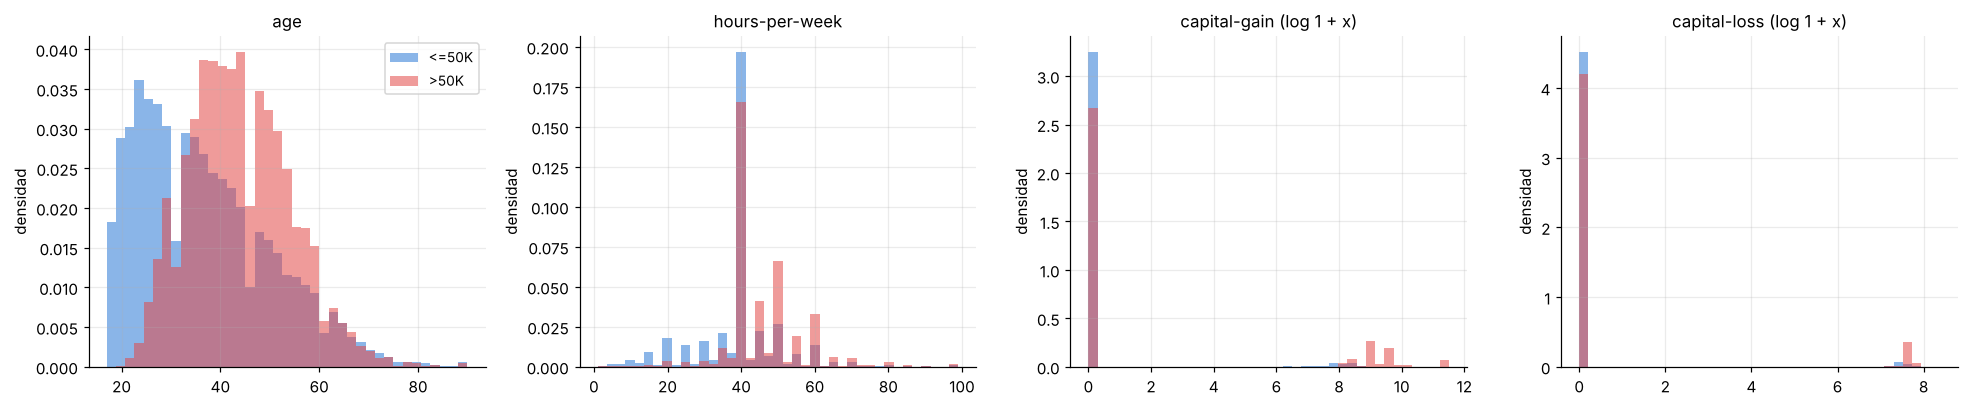

,media,mediana,máximo,% de ceros,media si <=50K,media si >50K
variable,,,,,,
age,38.4,37.0,90.0,0.0,36.6,44.0
hours-per-week,40.9,40.0,99.0,0.0,39.3,45.7
capital-gain,"1,092.0",0.0,"99,999.0",91.6,148.9,"3,937.7"
capital-loss,88.4,0.0,"4,356.0",95.3,53.4,193.8


capital-gain = 99999 en 148 filas (es un tope del censo), y 100% de ellas son >50K


In [3]:
# a) Variables numéricas: distribución por clase
NUM_COLS = ["age", "hours-per-week", "capital-gain", "capital-loss"]
y_train_txt = train_raw[TARGET]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col in zip(axes, NUM_COLS):
    datos = train_raw[col]
    if col.startswith("capital"):
        datos = np.log1p(datos)          # se grafica en escala log(1 + x): la mayoría vale 0 y unos pocos valores son enormes
    bins = np.linspace(datos.min(), datos.max(), 40)
    for clase, color in [("<=50K", C_BAJO), (">50K", C_ALTO)]:
        ax.hist(datos[y_train_txt == clase], bins=bins, alpha=0.55, color=color, label=clase, density=True)
    ax.set_title(col + (" (log 1 + x)" if col.startswith("capital") else ""))
    ax.set_ylabel("densidad")
axes[0].legend()
plt.tight_layout(); plt.show()

filas = []
for col in NUM_COLS:
    x = train_raw[col]
    filas.append({"variable": col, "media": x.mean(), "mediana": x.median(), "máximo": x.max(),
                  "% de ceros": 100 * (x == 0).mean(),
                  "media si <=50K": x[y_train_txt == "<=50K"].mean(), "media si >50K": x[y_train_txt == ">50K"].mean()})
display(pd.DataFrame(filas).set_index("variable").style.format("{:,.1f}"))
print(f"capital-gain = 99999 en {(train_raw['capital-gain'] == 99999).sum()} filas (es un tope del censo), "
      f"y {100 * (train_raw.loc[train_raw['capital-gain'] == 99999, TARGET] == '>50K').mean():.0f}% de ellas son >50K")


- `age` separa bastante bien: la mayoría de los que ganan más de 50K tienen entre 35 y 60 años, mientras que los menores de 25 casi nunca están en ese grupo. Media de 44 contra 37.
- `hours-per-week` tiene un pico enorme en 40 horas. Los de >50K trabajan algo más (46 contra 39 horas en promedio).
- `capital-gain` vale 0 en el 91,6% de las personas y `capital-loss` en el 95,3%, pero cuando aparecen pesan mucho: la ganancia media es 3.938 en >50K contra 149 en <=50K. Hay 148 personas con exactamente 99.999, que es un tope del censo, y todas son >50K.

Transformación: `age` y `hours-per-week` solo se estandarizan. A las de capital les aplicamos log(1 + x) antes de estandarizar. Sin eso, un 99.999 quedaría a más de 13 desvíos de la media y dominaría los primeros pasos del entrenamiento. El logaritmo achica esa escala, y el "+1" deja el 0 en 0.

##### Cardinalidad de las variables categóricas

El enunciado define alta cardinalidad como 10 valores únicos o más.

,valores únicos,valor más frecuente,% del más frecuente,cardinalidad
sex,2,Male,67.6,baja
race,5,White,86.0,baja
relationship,6,Husband,41.3,baja
workclass,7,Private,73.9,baja
marital-status,7,Married-civ-spouse,46.6,baja
occupation,14,Prof-specialty,13.4,alta
education,16,HS-grad,32.6,alta
native-country,41,United-States,91.2,alta
skill-profile,80,customer_service_retail,9.0,alta


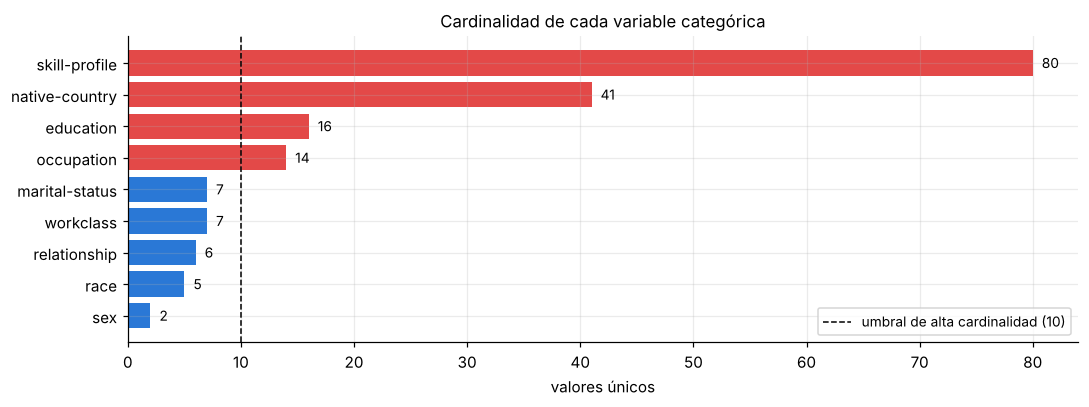

In [4]:
# a) Cardinalidad de las variables categóricas (alta cardinalidad = 10 o más valores únicos, según el enunciado)
CAT_COLS = [c for c in train_raw.columns if c not in NUM_COLS + [TARGET]]
card = pd.DataFrame({"valores únicos": train_raw[CAT_COLS].nunique(),
                     "valor más frecuente": train_raw[CAT_COLS].mode().iloc[0],
                     "% del más frecuente": [100 * train_raw[c].value_counts(normalize=True).iloc[0] for c in CAT_COLS]})
card["cardinalidad"] = np.where(card["valores únicos"] >= 10, "alta", "baja")
card = card.sort_values("valores únicos")
display(card.style.format({"% del más frecuente": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(card.index, card["valores únicos"], color=np.where(card["cardinalidad"] == "alta", C_ALTO, C_BAJO))
ax.axvline(10, color="k", ls="--", lw=1, label="umbral de alta cardinalidad (10)")
for i, v in enumerate(card["valores únicos"]):
    ax.text(v + 0.8, i, str(v), va="center", fontsize=9)
ax.set_xlabel("valores únicos"); ax.set_title("Cardinalidad de cada variable categórica"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()


Quedan cuatro variables de alta cardinalidad: `skill-profile` (80), `native-country` (41), `education` (16) y `occupation` (14). Las otras cinco tienen entre 2 y 7 valores.

`native-country` está muy concentrada: el 91,2% de las personas nació en Estados Unidos y hay países con 1 a 15 casos. Eso pesa en la decisión, porque con tan pocos casos cualquier representación de esos países se aprende con poca información.

##### Variables de baja cardinalidad frente al objetivo

Para cada categoría calculamos el porcentaje de personas con >50K. La línea punteada es el promedio general (24,9%).

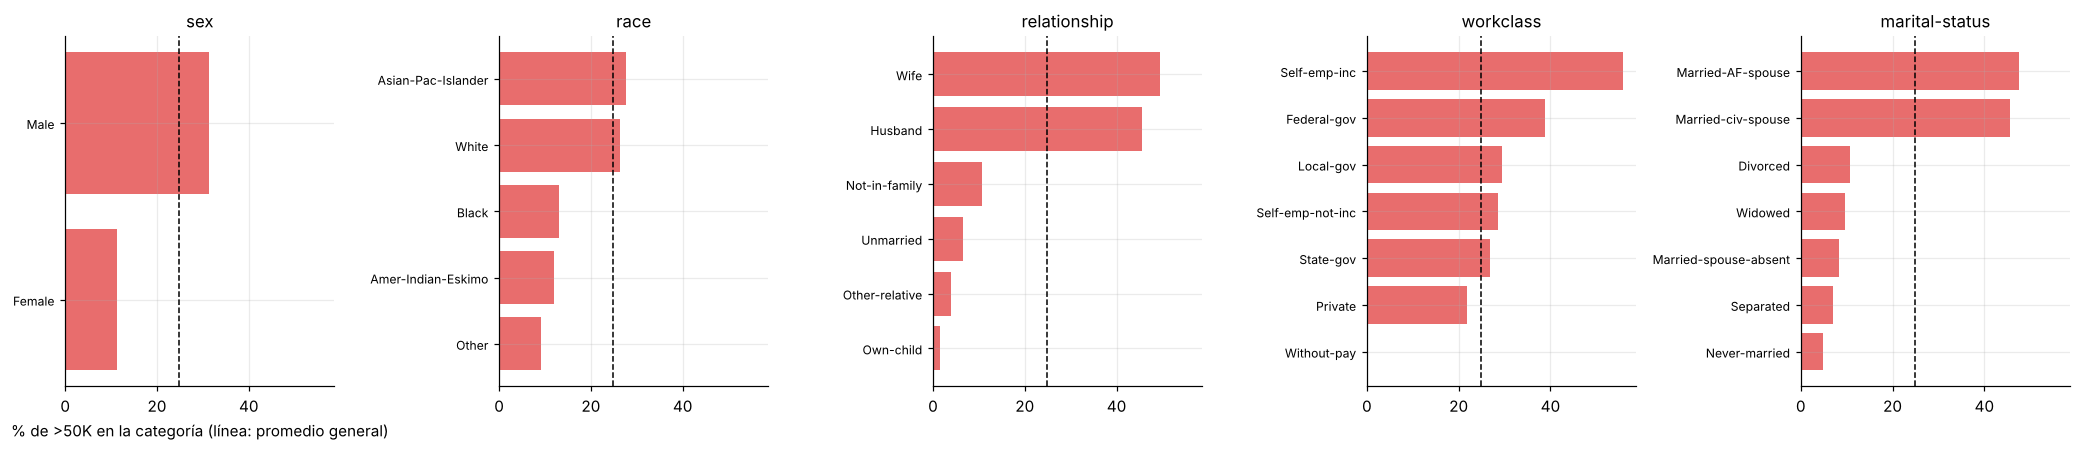

In [5]:
# a) Variables categóricas de baja cardinalidad: ¿cuánto cambia la proporción de >50K entre categorías?
y_train = (train_raw[TARGET] == ">50K").astype(int)
TASA_GLOBAL = y_train.mean()

def tasa_por_categoria(col):
    return (pd.DataFrame({"n": train_raw[col].value_counts(), "% >50K": 100 * y_train.groupby(train_raw[col]).mean()})
            .sort_values("% >50K"))

BAJAS = card.index[card["cardinalidad"] == "baja"].tolist()
fig, axes = plt.subplots(1, len(BAJAS), figsize=(19, 4.2), sharex=True)
for ax, col in zip(axes, BAJAS):
    t = tasa_por_categoria(col)
    ax.barh(t.index, t["% >50K"], color=C_ALTO, alpha=0.8)
    ax.axvline(100 * TASA_GLOBAL, color="k", ls="--", lw=1)
    ax.set_title(col); ax.tick_params(axis="y", labelsize=8)
axes[0].set_xlabel("% de >50K en la categoría (línea: promedio general)")
plt.tight_layout(); plt.show()
display(pd.concat({c: tasa_por_categoria(c) for c in ["relationship", "marital-status"]}).style.format({"% >50K": "{:.1f}", "n": "{:,.0f}"}))


- `relationship` y `marital-status` son las que más separan: en los casados (Husband, Wife, Married-civ-spouse) cerca de la mitad gana más de 50K, contra menos del 11% en el resto. Son casi la misma información vista de dos formas, y las dejamos a las dos porque cada una tiene matices propios (por ejemplo, "Own-child" casi nunca supera los 50K).
- `sex`: 31% de >50K en hombres contra 11% en mujeres.
- `workclass` y `race` separan menos. En `workclass` se destaca Self-emp-inc (56%), y "Without-pay" tiene solo 14 personas.

Ninguna de estas variables tiene un orden natural: "Wife" no es más ni menos que "Husband", ni "Private" más que "State-gov". Con tan pocos valores, one-hot es la opción más directa. Agrega pocas columnas (25 en total) y no le inventa a la red un orden que no existe. Para `sex`, al tener solo 2 valores, alcanza con una columna 0/1.

##### Variables de alta cardinalidad

Miramos las cuatro con el mismo criterio: cómo cambia el porcentaje de >50K entre sus valores y si hay un orden detrás. Al final medimos cuánto separa cada variable por sí sola, con el AUC que se obtiene usando solo la tasa de >50K de cada categoría (0,5 = no separa nada, 1 = separa perfecto).

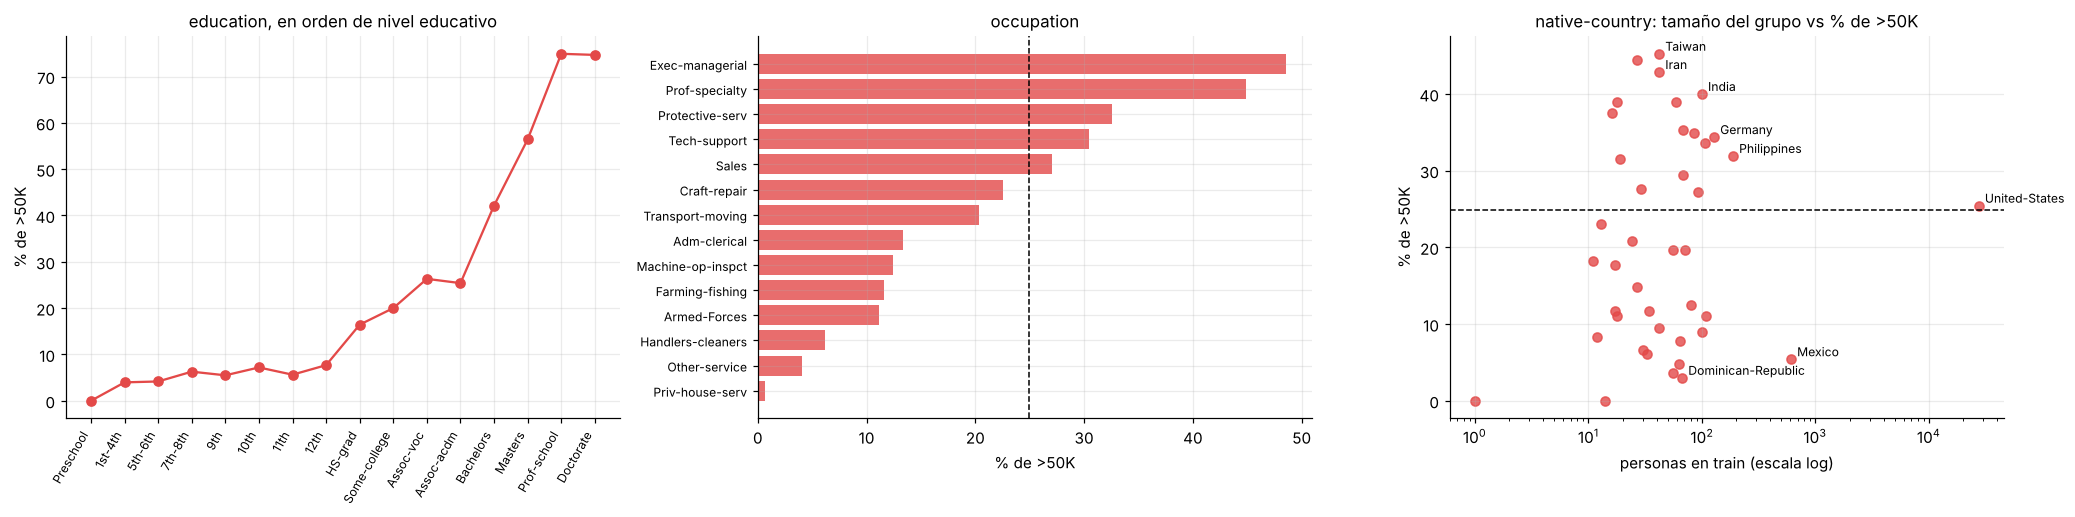

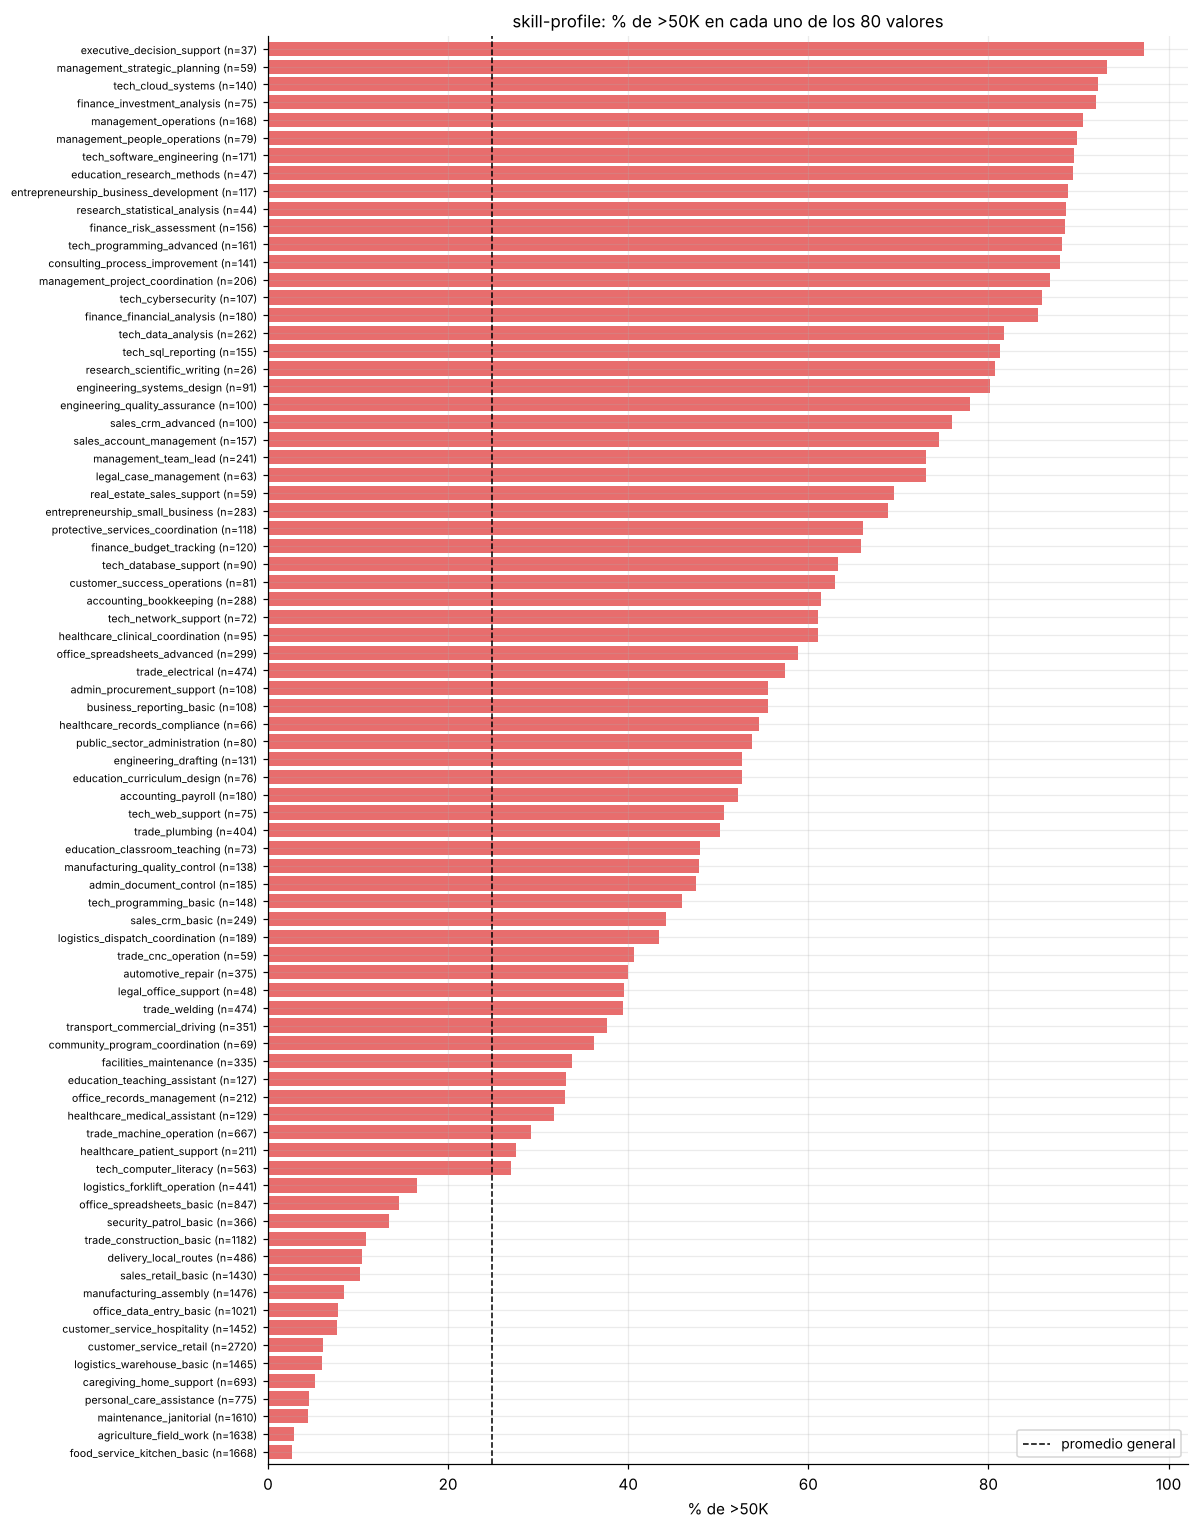

,AUC usando solo la tasa de >50K de cada categoría
skill-profile,0.866
relationship,0.777
marital-status,0.767
occupation,0.728
education,0.715
sex,0.617
workclass,0.568
race,0.537
native-country,0.531


Cada skill-profile aparece en 11 ocupaciones distintas (mediana); la ocupación más común de cada skill concentra solo el 47% de sus casos.


In [6]:
# a) Variables de alta cardinalidad: education, occupation, native-country y skill-profile
ORDEN_EDUCACION = ["Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th", "HS-grad",
                   "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors", "Masters", "Prof-school", "Doctorate"]
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

t = tasa_por_categoria("education").reindex(ORDEN_EDUCACION)
ax = axes[0]
ax.plot(range(len(t)), t["% >50K"], "o-", color=C_ALTO)
ax.set_xticks(range(len(t)), t.index, rotation=60, ha="right", fontsize=8)
ax.set_title("education, en orden de nivel educativo"); ax.set_ylabel("% de >50K")

t = tasa_por_categoria("occupation")
ax = axes[1]
ax.barh(t.index, t["% >50K"], color=C_ALTO, alpha=0.8)
ax.axvline(100 * TASA_GLOBAL, color="k", ls="--", lw=1)
ax.set_title("occupation"); ax.set_xlabel("% de >50K"); ax.tick_params(axis="y", labelsize=8)

t = tasa_por_categoria("native-country")
ax = axes[2]
ax.scatter(t["n"], t["% >50K"], color=C_ALTO, alpha=0.8)
for pais in ["United-States", "Mexico", "India", "Taiwan", "Iran", "Philippines", "Germany", "Dominican-Republic"]:
    if pais in t.index:
        ax.annotate(pais, (t.loc[pais, "n"], t.loc[pais, "% >50K"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xscale("log"); ax.axhline(100 * TASA_GLOBAL, color="k", ls="--", lw=1)
ax.set_title("native-country: tamaño del grupo vs % de >50K"); ax.set_xlabel("personas en train (escala log)"); ax.set_ylabel("% de >50K")

plt.tight_layout(); plt.show()

t = tasa_por_categoria("skill-profile")
fig, ax = plt.subplots(figsize=(11, 14))
ax.barh(range(len(t)), t["% >50K"], color=C_ALTO, alpha=0.8, height=0.8)
ax.set_yticks(range(len(t)), [f"{nombre} (n={n})" for nombre, n in zip(t.index, t["n"])], fontsize=7)
ax.axvline(100 * TASA_GLOBAL, color="k", ls="--", lw=1, label="promedio general")
ax.set_ylim(-0.7, len(t) - 0.3)
ax.set_title("skill-profile: % de >50K en cada uno de los 80 valores"); ax.set_xlabel("% de >50K"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

from sklearn.metrics import roc_auc_score
poder = {c: roc_auc_score(y_train, y_train.groupby(train_raw[c]).transform("mean")) for c in CAT_COLS}
display(pd.Series(poder, name="AUC usando solo la tasa de >50K de cada categoría").sort_values(ascending=False)
        .to_frame().style.format("{:.3f}"))

ct = pd.crosstab(train_raw["skill-profile"], train_raw["occupation"])
print(f"Cada skill-profile aparece en {ct.gt(0).sum(axis=1).median():.0f} ocupaciones distintas (mediana); "
      f"la ocupación más común de cada skill concentra solo el {100 * (ct.max(axis=1) / ct.sum(axis=1)).median():.0f}% de sus casos.")


- `education` tiene un orden real y los datos lo acompañan: el porcentaje de >50K sube casi siempre a medida que sube el nivel educativo, desde 0% en Preschool hasta 75% en Prof-school y Doctorate. Aunque tiene 16 valores, la tratamos como ordinal (0 a 15). Con un solo número la red recibe directamente ese orden. Un embedding tendría que redescubrirlo a partir de los datos, y one-hot lo perdería.
- `occupation` no tiene orden. Va de 0,7% (Priv-house-serv) a 48,5% (Exec-managerial), con muchos valores intermedios.
- `native-country` casi no separa (AUC 0,53): Estados Unidos está justo en el promedio, y el resto son grupos chicos con tasas muy dispersas, de 0 a 45%.
- `skill-profile` es la variable que más separa de todo el dataset (AUC 0,87, por encima de relationship con 0,78). Sus 80 valores van de 2,7% (food_service_kitchen_basic) a 97,3% (executive_decision_support). Además, no es una subdivisión de `occupation`: cada skill aparece en 11 ocupaciones distintas, así que aporta información propia.

Para `occupation`, `native-country` y `skill-profile` usamos embeddings. Son de alta cardinalidad y no tienen un orden que podamos imponer a mano. Con one-hot serían 135 columnas casi siempre en 0, y todas las categorías quedarían a la misma distancia entre sí. Con un embedding, la red aprende un vector corto para cada valor y puede acercar los que se comportan parecido, por ejemplo skills distintos del mismo rubro.

##### Decisión final por variable

La regla que seguimos, alineada con lo que vimos en clase: si la variable tiene un orden real, ordinal. Si tiene pocos valores y no tiene orden, one-hot. Si tiene 10 o más valores y no tiene orden, embedding.

Para la dimensión de los embeddings partimos de la regla práctica de la clase, raíz cuadrada de la cardinalidad dividida por 2, redondeada hacia arriba. En b) probamos duplicarla para ver si el modelo mejora.

In [7]:
# a) Decisión final por variable (el detalle de cada justificación está en el texto de abajo)
ORD_COLS = ["education"]                                         # alta cardinalidad, pero con orden real
BIN_COLS = ["sex"]                                               # binaria
OH_COLS = ["workclass", "marital-status", "relationship", "race"]  # baja cardinalidad, sin orden
EMB_COLS = ["occupation", "native-country", "skill-profile"]     # alta cardinalidad, sin orden
LOG_COLS = ["capital-gain", "capital-loss"]                      # muchos ceros y cola larga
assert sorted(ORD_COLS + BIN_COLS + OH_COLS + EMB_COLS) == sorted(CAT_COLS)

# Dimensión inicial de cada embedding: raíz cuadrada de la cardinalidad dividida por 2, redondeada hacia arriba
EMB_DIM_BASE = {c: int(np.ceil(np.sqrt(train_raw[c].nunique()) / 2)) for c in EMB_COLS}
decisiones = pd.DataFrame([
    *[{"variable": c, "tipo": "numérica", "transformación": "estandarizar"} for c in ["age", "hours-per-week"]],
    *[{"variable": c, "tipo": "numérica", "transformación": "log(1 + x) y estandarizar"} for c in LOG_COLS],
    {"variable": "education", "tipo": f"categórica ordenada ({train_raw['education'].nunique()} valores)", "transformación": "ordinal (0 a 15) y estandarizar"},
    {"variable": "sex", "tipo": "binaria", "transformación": "mapping 0/1"},
    *[{"variable": c, "tipo": f"categórica ({train_raw[c].nunique()} valores)", "transformación": "one-hot"} for c in OH_COLS],
    *[{"variable": c, "tipo": f"categórica ({train_raw[c].nunique()} valores)",
       "transformación": f"embedding de dimensión {EMB_DIM_BASE[c]}"} for c in EMB_COLS],
    {"variable": "income", "tipo": "objetivo binario", "transformación": ">50K = 1, <=50K = 0"},
]).set_index("variable")
display(decisiones)


,tipo,transformación
variable,,
age,numérica,estandarizar
hours-per-week,numérica,estandarizar
capital-gain,numérica,log(1 + x) y estandarizar
capital-loss,numérica,log(1 + x) y estandarizar
education,categórica ordenada (16 valores),ordinal (0 a 15) y estandarizar
sex,binaria,mapping 0/1
workclass,categórica (7 valores),one-hot
marital-status,categórica (7 valores),one-hot
relationship,categórica (6 valores),one-hot


| Variable | Decisión | Por qué |
|---|---|---|
| `age`, `hours-per-week` | estandarizar | numéricas con escala razonable |
| `capital-gain`, `capital-loss` | log(1 + x) y estandarizar | más del 90% en cero y una cola de hasta 99.999 |
| `education` | ordinal (0-15) y estandarizar | alta cardinalidad, pero con orden real que los datos confirman |
| `sex` | mapping 0/1 | binaria |
| `workclass`, `marital-status`, `relationship`, `race` | one-hot | entre 5 y 7 valores, sin orden |
| `occupation` | embedding de dimensión 2 | 14 valores sin orden: raíz(14)/2 = 1,9 |
| `native-country` | embedding de dimensión 4 | 41 valores sin orden: raíz(41)/2 = 3,2 |
| `skill-profile` | embedding de dimensión 5 | 80 valores sin orden: raíz(80)/2 = 4,5 |
| `income` | >50K = 1, <=50K = 0 | objetivo binario |

No usamos label encoding en ninguna variable nominal, porque le asignaría a cada categoría un número arbitrario y la red lo leería como un orden. Lo único que se parece a eso es el 0/1 de `sex`, que con dos valores es equivalente a un one-hot.

## b) Diseño y entrenamiento de un modelo con embeddings (3 puntos)

- Implementar las transformaciones definidas en el punto anterior e incorporarlas al flujo de entrenamiento.
- El modelo debe incluir, como mínimo, una capa de embedding para representar alguna de las variables categóricas.
- La elección de la dimensión del o los embeddings queda a criterio del estudiante, pero debe estar correctamente fundamentada. Recuerden que no es obligatorio que todos los embeddings tengan la misma dimensión.
- La configuración arquitectónica (número de capas, neuronas por capa, función de activación) es de libre elección.
- Incluir dropout en las capas ocultas de la red.
- Utilizar Adam o alguna de sus variantes como optimizador.
- Seleccionar la función de costo apropiada entre Binary CrossEntropyLoss o Categorical CrossEntropyLoss, según la formulación del problema.
- Mostrar las curvas de accuracy vs epoch y F1 macro vs epoch para los sets de entrenamiento y validación.
- Presentar un classification report generado con sklearn.
- Presentar una matriz de confusión absoluta y otra normalizada por fila, correspondientes al set de validación, con una paleta de colores entendible.

### Resolución b)

##### Preprocesamiento

`Preprocesador` aplica las decisiones de a) y se ajusta solo con datos de entrenamiento: la media y el desvío para estandarizar, y el vocabulario de cada variable categórica. Tiene dos modos. En el modo "embeddings", `occupation`, `native-country` y `skill-profile` salen como índices enteros que después busca cada capa `nn.Embedding`. En el modo "onehot", las mismas tres variables se suman al one-hot (es lo que usa el modelo de c).

En cada embedding reservamos el índice 0 para valores que no aparezcan en entrenamiento. En clase se mencionó que una categoría nueva rompe un embedding entrenado. Con este índice, el modelo no falla: la trata como "desconocida". En este dataset pasa con un solo caso (Holand-Netherlands está en train y no en validation), pero en uso real puede pasar más seguido.

Además separamos un 15% de train, estratificado por clase, como set de ajuste. Con ese set elegimos la mejor época y los hiperparámetros. El set de validation del enunciado lo usamos solo para mostrar curvas y reportar resultados, sin tomar decisiones con él.

In [8]:
# b) Preprocesamiento: todo se ajusta SOLO con los datos de entrenamiento
class Preprocesador:
    """Convierte un DataFrame crudo en tensores para la red.
    modo="embeddings": las columnas de EMB_COLS salen como índices enteros (para nn.Embedding).
    modo="onehot":     las columnas de EMB_COLS se suman al one-hot (es el modelo del punto c).
    El índice 0 de cada embedding queda reservado para categorías que no aparecieron en train."""
    def fit(self, df):
        self.escalador = StandardScaler().fit(self._numericas(df))
        self.vocab_oh = {c: sorted(df[c].unique()) for c in OH_COLS + EMB_COLS}
        self.vocab_emb = {c: {v: i + 1 for i, v in enumerate(sorted(df[c].unique()))} for c in EMB_COLS}
        return self

    def _numericas(self, df):
        out = pd.DataFrame(index=df.index)
        out[["age", "hours-per-week"]] = df[["age", "hours-per-week"]].astype(float)
        for c in LOG_COLS:
            out[c] = np.log1p(df[c])
        out["education"] = df["education"].map({v: i for i, v in enumerate(ORDEN_EDUCACION)})
        return out

    def _onehot(self, df, columnas):
        partes = [pd.get_dummies(pd.Categorical(df[c], categories=self.vocab_oh[c]), prefix=c, dtype=np.float32)
                  for c in columnas]
        return pd.concat(partes, axis=1).set_index(df.index)

    def transform(self, df, modo):
        num = pd.DataFrame(self.escalador.transform(self._numericas(df)), index=df.index,
                           columns=["age", "hours-per-week", *LOG_COLS, "education"])
        num["sex_Male"] = (df["sex"] == "Male").astype(float)
        cols_oh = OH_COLS + (EMB_COLS if modo == "onehot" else [])
        X_denso = pd.concat([num, self._onehot(df, cols_oh)], axis=1).astype(np.float32)
        X_idx = (np.stack([df[c].map(self.vocab_emb[c]).fillna(0).astype(int).to_numpy() for c in EMB_COLS], axis=1)
                 if modo == "embeddings" else np.zeros((len(df), 0), dtype=int))
        y = (df[TARGET] == ">50K").astype(np.float32).to_numpy()
        return X_denso, X_idx, y

# Separamos un 15% de train (estratificado) como "validación interna": con ella elegimos épocas e hiperparámetros.
# Así el set de validation del enunciado queda limpio para reportar los resultados finales.
from sklearn.model_selection import train_test_split
fit_df, ajuste_df = train_test_split(train_raw, test_size=0.15, random_state=SEED, stratify=train_raw[TARGET])
prep = Preprocesador().fit(fit_df)
SPLITS = {"train": fit_df, "ajuste": ajuste_df, "validation": val_raw}

def tensores(modo):
    out = {}
    for nombre, df in SPLITS.items():
        Xd, Xi, y = prep.transform(df, modo)
        out[nombre] = (torch.tensor(Xd.to_numpy()), torch.tensor(Xi, dtype=torch.long), torch.tensor(y).unsqueeze(1))
    out["columnas"] = list(Xd.columns)
    return out

DATOS = {"embeddings": tensores("embeddings"), "onehot": tensores("onehot")}
CARDINALIDAD = {c: len(prep.vocab_emb[c]) + 1 for c in EMB_COLS}   # +1 por el índice reservado a "desconocido"
for modo, d in DATOS.items():
    print(f"modo {modo:<10}: {d['train'][0].shape[1]:>3} columnas densas + {d['train'][1].shape[1]} columnas de índices "
          f"| train {len(d['train'][2]):,} · ajuste {len(d['ajuste'][2]):,} · validation {len(d['validation'][2]):,}")


modo embeddings:  31 columnas densas + 3 columnas de índices | train 25,637 · ajuste 4,525 · validation 15,060
modo onehot    : 166 columnas densas + 0 columnas de índices | train 25,637 · ajuste 4,525 · validation 15,060


##### La red

`RedTabular` busca el vector de cada variable con embedding, lo concatena con las columnas numéricas y one-hot, y pasa todo por un MLP de tres capas ocultas (128, 64 y 32 neuronas). Cada capa oculta es Linear → LeakyReLU → Dropout, en ese orden, como se vio en clase: el dropout va después de la activación y nunca en la capa de salida. Usamos LeakyReLU, que fue la recomendación de la clase para modelos con embeddings: deja pasar un poco de gradiente en los valores negativos, así ninguna neurona queda apagada para siempre.

La salida es un solo número (logit), y la función de costo es `BCEWithLogitsLoss`, la Binary CrossEntropy con la sigmoide incluida. Elegimos Binary y no Categorical CrossEntropy porque el problema tiene dos clases excluyentes: una sola probabilidad, la de >50K, alcanza para describirlo. Categorical CrossEntropy necesitaría dos salidas que siempre suman 1, o sea, dos números para decir lo mismo. La versión "with logits" es además más estable numéricamente que aplicar la sigmoide por separado.

`entrenar` usa Adam con learning rate 0,001 y batch de 256. Antes de recorrer los lotes de cada época llama a `model.train()` (dropout encendido) y antes de medir llama a `model.eval()` (dropout apagado). Al final de cada época mide accuracy y F1 macro en train, ajuste y validation, y se queda con los pesos de la época con mejor F1 macro en ajuste (early stopping).

In [9]:
# b) La red: embeddings para las variables de alta cardinalidad + MLP con dropout
class RedTabular(nn.Module):
    """Concatena las columnas densas con los vectores de embedding y los pasa por un MLP.
    Cada capa oculta es Linear -> LeakyReLU -> Dropout (si dropout > 0). Si dropout == 0 no se crea ninguna capa de Dropout.
    La salida es un solo logit (clasificación binaria con BCEWithLogitsLoss)."""
    def __init__(self, n_densas, emb_dims=None, ocultas=(128, 64, 32), dropout=0.3, emb_std=1.0):
        super().__init__()
        emb_dims = emb_dims or {}
        self.embeddings = nn.ModuleList([nn.Embedding(CARDINALIDAD[c], emb_dims[c]) for c in EMB_COLS if c in emb_dims])
        for emb in self.embeddings:
            nn.init.normal_(emb.weight, mean=0.0, std=emb_std)   # inicialización normal; el desvío se elige en el experimento 1
        capas, ancho = [], n_densas + sum(emb_dims.values())
        for n in ocultas:
            capas += [nn.Linear(ancho, n), nn.LeakyReLU()]
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
            ancho = n
        capas.append(nn.Linear(ancho, 1))
        self.mlp = nn.Sequential(*capas)
        self.n_entradas = n_densas + sum(emb_dims.values())

    def forward(self, x_denso, x_idx):
        vectores = [emb(x_idx[:, i]) for i, emb in enumerate(self.embeddings)]
        return self.mlp(torch.cat([x_denso, *vectores], dim=1))

def contar_parametros(modelo):
    total = sum(p.numel() for p in modelo.parameters())
    emb = sum(p.numel() for e in modelo.embeddings for p in e.parameters())
    return total, emb

def peso_en_disco(modelo):
    """Tamaño en KB del archivo que se guardaría con torch.save(state_dict)."""
    buffer = io.BytesIO(); torch.save(modelo.state_dict(), buffer)
    return buffer.getbuffer().nbytes / 1024

def predecir(modelo, datos):
    modelo.eval()
    with torch.no_grad():
        return torch.sigmoid(modelo(datos[0], datos[1])).numpy().ravel()

def metricas(modelo, datos, umbral=0.5):
    p = predecir(modelo, datos); y = datos[2].numpy().ravel()
    pred = (p >= umbral).astype(int)
    return {"loss": nn.functional.binary_cross_entropy(torch.tensor(p).clamp(1e-7, 1 - 1e-7), torch.tensor(y)).item(),
            "accuracy": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, average="macro")}

CONFIG_BASE = dict(modo="embeddings", emb_std=1.0, emb_mult=1, dropout=0.3, ocultas=(128, 64, 32), lr=1e-3,
                   batch_size=256, epocas=40, pos_weight=None)

def entrenar(config=None, semilla=SEED, verbose=False):
    """Entrena con Adam y BCEWithLogitsLoss. En cada época mide train, ajuste y validation (con model.eval()).
    Se queda con los pesos de la época con mejor F1 macro en el set de AJUSTE (early stopping), nunca mirando validation."""
    cfg = {**CONFIG_BASE, **(config or {})}
    datos = DATOS[cfg["modo"]]
    torch.manual_seed(semilla)
    emb_dims = {c: EMB_DIM_BASE[c] * cfg["emb_mult"] for c in EMB_COLS} if cfg["modo"] == "embeddings" else {}
    modelo = RedTabular(datos["train"][0].shape[1], emb_dims, cfg["ocultas"], cfg["dropout"], cfg["emb_std"])
    pw = None if cfg["pos_weight"] is None else torch.tensor([cfg["pos_weight"]])
    perdida_fn = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.Adam(modelo.parameters(), lr=cfg["lr"])
    cargador = DataLoader(TensorDataset(*datos["train"]), batch_size=cfg["batch_size"], shuffle=True,
                          generator=torch.Generator().manual_seed(semilla))
    hist = {f"{m}_{s}": [] for m in ("loss", "accuracy", "f1_macro") for s in ("train", "ajuste", "validation")}
    mejor = {"f1": -1, "epoca": 0, "estado": None}
    t0 = time.perf_counter()
    for epoca in range(1, cfg["epocas"] + 1):
        modelo.train()                                   # dropout encendido
        for xd, xi, yb in cargador:
            opt.zero_grad()
            perdida_fn(modelo(xd, xi), yb).backward()
            opt.step()
        for s in ("train", "ajuste", "validation"):      # metricas() pone el modelo en eval(): dropout apagado
            for k, v in metricas(modelo, datos[s]).items():
                hist[f"{k}_{s}"].append(v)
        if hist["f1_macro_ajuste"][-1] > mejor["f1"]:
            mejor = {"f1": hist["f1_macro_ajuste"][-1], "epoca": epoca, "estado": copy.deepcopy(modelo.state_dict())}
    segundos = time.perf_counter() - t0
    modelo.load_state_dict(mejor["estado"])
    return modelo, {k: np.array(v) for k, v in hist.items()}, mejor, segundos / cfg["epocas"]

modelo_prueba, hist_prueba, mejor_prueba, seg = entrenar()
total, emb = contar_parametros(modelo_prueba)
print(f"Dimensiones de embedding iniciales: {EMB_DIM_BASE} | entradas al MLP: {modelo_prueba.n_entradas}")
print(f"Parámetros: {total:,} ({emb:,} en embeddings) | {seg:.1f} s por época | mejor época (ajuste): {mejor_prueba['epoca']}")
print(modelo_prueba)


Dimensiones de embedding iniciales: {'occupation': 2, 'native-country': 4, 'skill-profile': 5} | entradas al MLP: 42
Parámetros: 16,476 (603 en embeddings) | 0.5 s por época | mejor época (ajuste): 24
RedTabular(
  (embeddings): ModuleList(
    (0): Embedding(15, 2)
    (1): Embedding(42, 4)
    (2): Embedding(81, 5)
  )
  (mlp): Sequential(
    (0): Linear(in_features=42, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): LeakyReLU(negative_slope=0.01)
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=32, out_features=1, bias=True)
  )
)


Con las dimensiones iniciales (2, 4 y 5), a la primera capa oculta le entran 42 números por persona: 31 columnas densas (5 numéricas y ordinales, el 0/1 de sexo y 25 de one-hot) más 11 de embeddings. La red tiene 16.476 parámetros, de los cuales 603 son los vectores de los embeddings.

##### Experimentos

Antes de fijar la configuración probamos cuatro cosas, de a una por vez y siempre con 3 semillas (cambian la inicialización y el orden de los lotes). La regla para decidir: cambiamos la opción por defecto solo si la alternativa le gana en F1 macro de ajuste por más que el desvío entre semillas. Si no, la diferencia puede ser casualidad y nos quedamos con la opción más simple.

1. La escala de la inicialización normal de los embeddings.
2. La dimensión de los embeddings: la regla de raíz(n)/2, duplicada y cuadruplicada, como se sugirió en clase ("duplicar mientras el error baje").
3. La probabilidad de dropout, dentro del rango 0,2 a 0,4 recomendado en clase.
4. Si conviene darle más peso a la clase >50K en el costo (`pos_weight`), dado que es solo el 25% de los datos.

,F1 macro (ajuste),± desvío,accuracy (ajuste),F1 macro (train),mejor época (mediana),parámetros
variante,,,,,,
"N(0, 1.0)",0.8396,0.0034,0.8834,0.8679,33,"16,476"
"N(0, 0.1)",0.8482,0.0042,0.8894,0.8629,22,"16,476"
"N(0, 0.01)",0.8474,0.0012,0.8890,0.8662,36,"16,476"


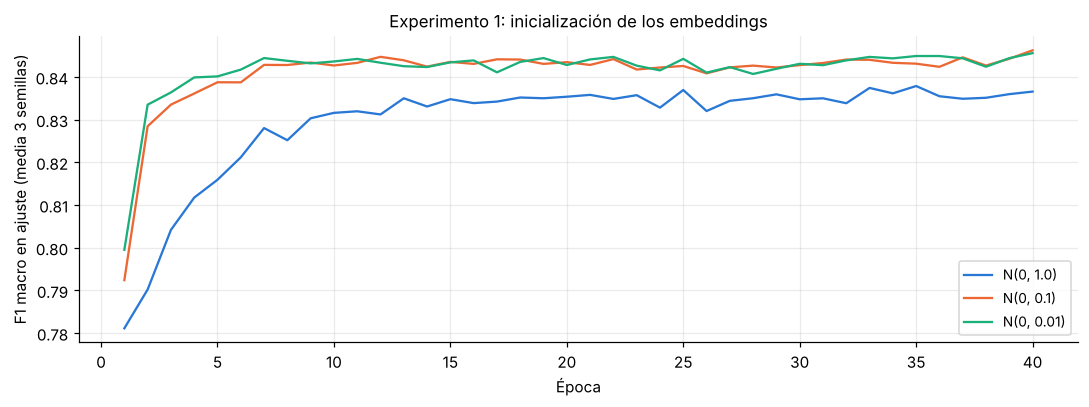

Inicialización elegida: N(0, 0.1)


Orden de las dimensiones: ['occupation', 'native-country', 'skill-profile']


,F1 macro (ajuste),± desvío,accuracy (ajuste),F1 macro (train),mejor época (mediana),parámetros
variante,,,,,,
"x1: dimensiones 2, 4, 5",0.8482,0.0042,0.8894,0.8629,22,"16,476"
"x2: dimensiones 4, 8, 10",0.8473,0.0016,0.8886,0.8720,33,"18,487"
"x4: dimensiones 8, 16, 20",0.8448,0.0014,0.8869,0.8569,12,"22,509"


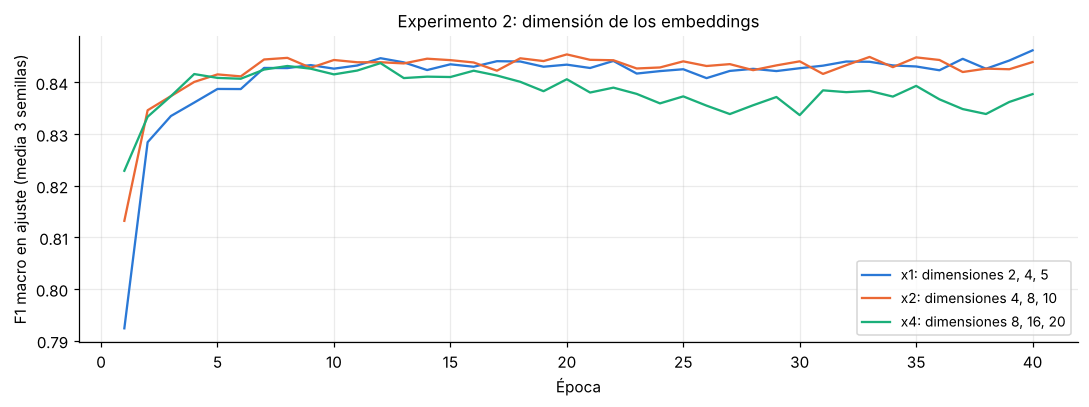

Dimensiones elegidas: {'occupation': 2, 'native-country': 4, 'skill-profile': 5}


In [10]:
# b) Experimentos para fijar dimensión de embeddings, dropout y peso de la clase positiva (3 semillas cada uno)
SEMILLAS = (0, 1, 2)
DECISIONES = []

def experimento(variantes, base):
    filas, historias = [], {}
    for nombre, cambios in variantes.items():
        corridas = []
        for s in SEMILLAS:
            modelo, h, mejor, seg = entrenar({**base, **cambios}, semilla=s)
            historias[(nombre, s)] = h
            e = mejor["epoca"] - 1
            corridas.append({"f1_ajuste": mejor["f1"], "acc_ajuste": h["accuracy_ajuste"][e], "epoca": mejor["epoca"],
                             "f1_train": h["f1_macro_train"][e], "params": contar_parametros(modelo)[0]})
        c = pd.DataFrame(corridas)
        filas.append({"variante": nombre, "F1 macro (ajuste)": c["f1_ajuste"].mean(), "± desvío": c["f1_ajuste"].std(),
                      "accuracy (ajuste)": c["acc_ajuste"].mean(), "F1 macro (train)": c["f1_train"].mean(),
                      "mejor época (mediana)": c["epoca"].median(), "parámetros": c["params"].iloc[0]})
    return pd.DataFrame(filas).set_index("variante"), historias

FMT_EXP = {"F1 macro (ajuste)": "{:.4f}", "± desvío": "{:.4f}", "accuracy (ajuste)": "{:.4f}",
           "F1 macro (train)": "{:.4f}", "mejor época (mediana)": "{:.0f}", "parámetros": "{:,.0f}"}

def elegir(tabla, por_defecto, nombre_exp, orden=None):
    """Nos quedamos con la opción por defecto salvo que otra le gane por más que el desvío entre semillas."""
    mejor = tabla["F1 macro (ajuste)"].idxmax()
    dif = tabla.loc[mejor, "F1 macro (ajuste)"] - tabla.loc[por_defecto, "F1 macro (ajuste)"]
    ruido = max(tabla.loc[mejor, "± desvío"], tabla.loc[por_defecto, "± desvío"])
    elegida = mejor if dif > ruido else por_defecto
    DECISIONES.append({"experimento": nombre_exp, "por defecto": por_defecto, "mejor variante": mejor,
                       "diferencia de F1": dif, "desvío entre semillas": ruido, "elegida": elegida})
    return elegida

def curvas_experimento(historias, tabla, titulo):
    fig, ax = plt.subplots(figsize=(10, 3.8))
    colores = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]
    for i, nombre in enumerate(tabla.index):
        curvas = np.array([h["f1_macro_ajuste"] for (n, _), h in historias.items() if n == nombre])
        ax.plot(np.arange(1, curvas.shape[1] + 1), curvas.mean(axis=0), color=colores[i % 4], label=nombre)
    ax.set_xlabel("Época"); ax.set_ylabel("F1 macro en ajuste (media 3 semillas)"); ax.set_title(titulo); ax.legend()
    plt.tight_layout(); plt.show()

config = dict(CONFIG_BASE)

# Experimento 1: escala de la inicialización normal de los embeddings (1.0 es el valor por defecto de PyTorch)
tabla_init, hist_init = experimento({f"N(0, {s})": {"emb_std": s} for s in (1.0, 0.1, 0.01)}, config)
display(tabla_init.style.format(FMT_EXP))
curvas_experimento(hist_init, tabla_init, "Experimento 1: inicialización de los embeddings")
elegida = elegir(tabla_init, "N(0, 1.0)", "inicialización de embeddings")
config["emb_std"] = float(elegida[4:-1])
print("Inicialización elegida:", elegida)

# Experimento 2: dimensión de los embeddings. Arrancamos en raíz(n)/2 y duplicamos.
tabla_dim, hist_dim = experimento({f"x{m}: dimensiones " + ", ".join(str(EMB_DIM_BASE[c] * m) for c in EMB_COLS): {"emb_mult": m}
                                   for m in (1, 2, 4)}, config)
print("Orden de las dimensiones:", EMB_COLS)
display(tabla_dim.style.format(FMT_EXP))
curvas_experimento(hist_dim, tabla_dim, "Experimento 2: dimensión de los embeddings")
elegida = elegir(tabla_dim, tabla_dim.index[0], "dimensión de embeddings")
config["emb_mult"] = int(elegida.split(":")[0][1:])
EMB_DIMS = {c: EMB_DIM_BASE[c] * config["emb_mult"] for c in EMB_COLS}
print("Dimensiones elegidas:", EMB_DIMS)


Inicialización. Es el experimento que más movió el resultado. Con la inicialización por defecto de PyTorch, N(0, 1), el F1 macro en ajuste queda en 0,840 y la curva tarda en subir. Con N(0, 0,1) llega a 0,848 y con N(0, 0,01) a 0,847: una diferencia de 0,008, el doble del ruido entre semillas. La explicación es de escala. Con desvío 1, cada categoría arranca con un vector aleatorio grande, comparable a las features estandarizadas, y la red aprende a usarlo como un código fijo en lugar de ajustarlo. Con desvío 0,1, los vectores arrancan cerca de cero y se van ubicando según lo que sirve para predecir. Más abajo se ve que, con esta inicialización, los embeddings quedan ordenados según el ingreso. Nos quedamos con N(0, 0,1).

Dimensión. Duplicar las dimensiones (4, 8 y 10) da prácticamente lo mismo (0,847) y cuadruplicarlas (8, 16 y 20) empeora un poco (0,845), mientras los parámetros pasan de 16.476 a 22.509. Siguiendo la regla de la clase, "duplicar mientras el error baje", acá el error no baja al duplicar, así que nos quedamos con las dimensiones iniciales: 2 para occupation, 4 para native-country y 5 para skill-profile.

,F1 macro (ajuste),± desvío,accuracy (ajuste),F1 macro (train),mejor época (mediana),parámetros
variante,,,,,,
dropout 0.2,0.8495,0.0001,0.8904,0.8674,28,"16,476"
dropout 0.3,0.8482,0.0042,0.8894,0.8629,22,"16,476"
dropout 0.4,0.8463,0.0013,0.8892,0.8614,37,"16,476"


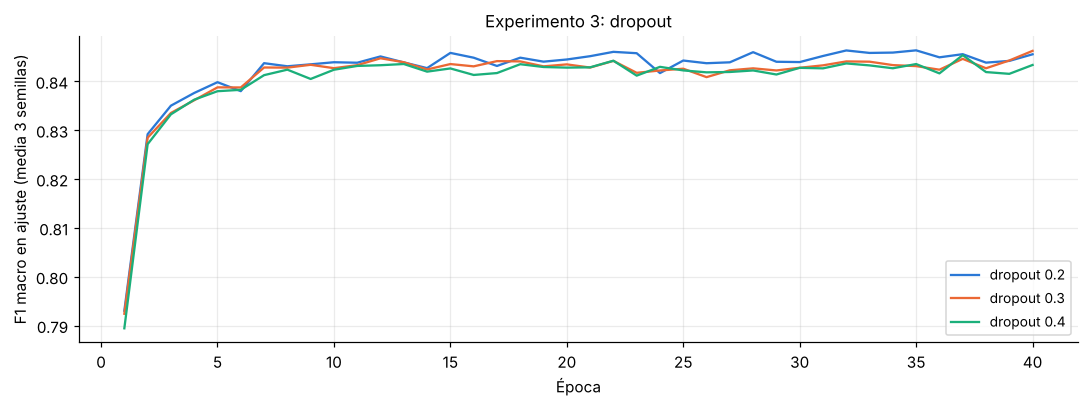

,F1 macro (ajuste),± desvío,accuracy (ajuste),F1 macro (train),mejor época (mediana),parámetros
variante,,,,,,
sin pos_weight,0.8482,0.0042,0.8894,0.8629,22,"16,476"
pos_weight = 3.02,0.8429,0.0021,0.8745,0.8611,33,"16,476"


,por defecto,mejor variante,diferencia de F1,desvío entre semillas,elegida
experimento,,,,,
inicialización de embeddings,"N(0, 1.0)","N(0, 0.1)",+0.0086,0.0042,"N(0, 0.1)"
dimensión de embeddings,"x1: dimensiones 2, 4, 5","x1: dimensiones 2, 4, 5",+0.0000,0.0042,"x1: dimensiones 2, 4, 5"
dropout,dropout 0.3,dropout 0.2,+0.0013,0.0042,dropout 0.3
peso de la clase >50K,sin pos_weight,sin pos_weight,+0.0000,0.0042,sin pos_weight


Configuración final del modelo con embeddings: {'modo': 'embeddings', 'emb_std': 0.1, 'emb_mult': 1, 'dropout': 0.3, 'ocultas': (128, 64, 32), 'lr': 0.001, 'batch_size': 256, 'epocas': 40, 'pos_weight': None}


In [11]:
# Experimento 3: probabilidad de dropout, dentro del rango 0.2 - 0.4 recomendado en clase
tabla_drop, hist_drop = experimento({f"dropout {p}": {"dropout": p} for p in (0.2, 0.3, 0.4)}, config)
display(tabla_drop.style.format(FMT_EXP))
curvas_experimento(hist_drop, tabla_drop, "Experimento 3: dropout")
config["dropout"] = float(elegir(tabla_drop, "dropout 0.3", "dropout").split()[-1])

# Experimento 4: clases desbalanceadas (25% de >50K). pos_weight multiplica el error en los positivos.
PESO_BALANCEADO = float((1 - fit_df[TARGET].eq(">50K").mean()) / fit_df[TARGET].eq(">50K").mean())
tabla_pw, hist_pw = experimento({"sin pos_weight": {"pos_weight": None},
                                 f"pos_weight = {PESO_BALANCEADO:.2f}": {"pos_weight": PESO_BALANCEADO}}, config)
display(tabla_pw.style.format(FMT_EXP))
eleg = elegir(tabla_pw, "sin pos_weight", "peso de la clase >50K")
config["pos_weight"] = None if eleg == "sin pos_weight" else PESO_BALANCEADO

display(pd.DataFrame(DECISIONES).set_index("experimento").style.format(
    {"diferencia de F1": "{:+.4f}", "desvío entre semillas": "{:.4f}"}).set_caption("Resumen de decisiones"))
CONFIG_EMB = dict(config)
print("Configuración final del modelo con embeddings:", CONFIG_EMB)


Dropout. Las tres probabilidades quedan dentro del ruido (0,850, 0,848 y 0,846). Nos quedamos con 0,3, en el medio del rango recomendado. Se ve que, a más dropout, menor es el F1 de train, o sea, la red memoriza menos.

pos_weight. Darle tres veces más peso a la clase >50K empeora un poco el F1 macro (0,843 contra 0,848) y baja la accuracy de 0,889 a 0,875. Lo que hace es correr el equilibrio: el modelo detecta más casos de >50K, pero se equivoca más con los de <=50K. Como la consigna mide F1 macro y no prioriza una clase sobre otra, no lo usamos.

Configuración final del modelo con embeddings: embeddings de dimensión 2, 4 y 5 inicializados con N(0, 0,1), capas ocultas de 128, 64 y 32 con LeakyReLU, dropout de 0,3, Adam con 0,001, batch de 256, Binary CrossEntropy sin pesos, hasta 40 épocas con early stopping.

##### Modelo final con embeddings

Entrenamos la configuración elegida con la semilla del TP. Las curvas muestran accuracy y F1 macro en train y en validation, época por época. La línea punteada marca la época que eligió el early stopping usando el set de ajuste.

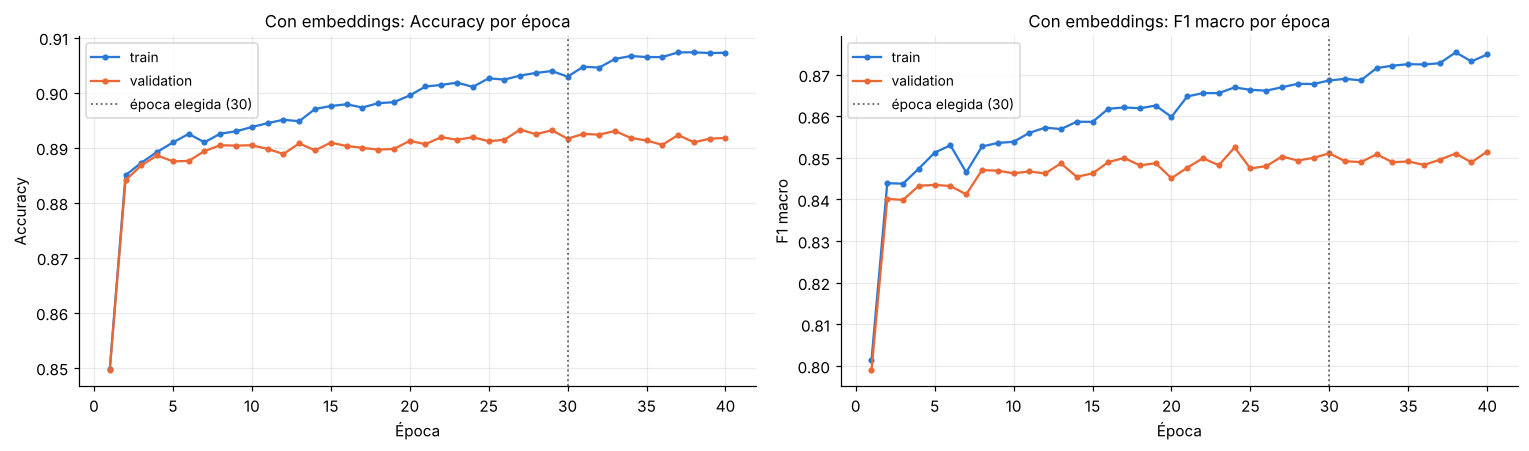

Época elegida 30: accuracy train 0.9029 | validation 0.8916  ·  F1 macro train 0.8686 | validation 0.8511
Última época: F1 macro train 0.8748 | validation 0.8515


In [12]:
# b) Modelo final con embeddings: curvas de accuracy y F1 macro por época (train y validation)
modelo_emb, hist_emb, mejor_emb, seg_emb = entrenar(CONFIG_EMB, semilla=SEED)

def graficar_curvas(hist, mejor, titulo):
    ep = np.arange(1, len(hist["accuracy_train"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    for ax, m, nombre in [(axes[0], "accuracy", "Accuracy"), (axes[1], "f1_macro", "F1 macro")]:
        ax.plot(ep, hist[f"{m}_train"], "o-", ms=3, color=C_TRAIN, label="train")
        ax.plot(ep, hist[f"{m}_validation"], "o-", ms=3, color=C_VAL, label="validation")
        ax.axvline(mejor["epoca"], color="0.4", ls=":", lw=1.2, label=f"época elegida ({mejor['epoca']})")
        ax.set_xlabel("Época"); ax.set_ylabel(nombre); ax.set_title(f"{titulo}: {nombre} por época"); ax.legend()
    plt.tight_layout(); plt.show()
    e = mejor["epoca"] - 1
    print(f"Época elegida {mejor['epoca']}: accuracy train {hist['accuracy_train'][e]:.4f} | validation {hist['accuracy_validation'][e]:.4f}"
          f"  ·  F1 macro train {hist['f1_macro_train'][e]:.4f} | validation {hist['f1_macro_validation'][e]:.4f}")
    print(f"Última época: F1 macro train {hist['f1_macro_train'][-1]:.4f} | validation {hist['f1_macro_validation'][-1]:.4f}")

graficar_curvas(hist_emb, mejor_emb, "Con embeddings")


Las dos curvas suben juntas las primeras 3 épocas y después se separan de a poco. Train sigue mejorando hasta 0,875 de F1 macro, mientras validation se estabiliza alrededor de 0,85 desde la época 10. La brecha final es chica (0,023), y validation nunca empieza a bajar. Es lo que se espera con dropout: la red aprende lo general y no llega a memorizar los casos de train. El early stopping eligió la época 30, con accuracy de 0,892 y F1 macro de 0,851 en validation.

              precision    recall  f1-score   support

       <=50K     0.9208    0.9370    0.9288     11360
        >50K     0.7954    0.7524    0.7733      3700

    accuracy                         0.8916     15060
   macro avg     0.8581    0.8447    0.8511     15060
weighted avg     0.8900    0.8916    0.8906     15060



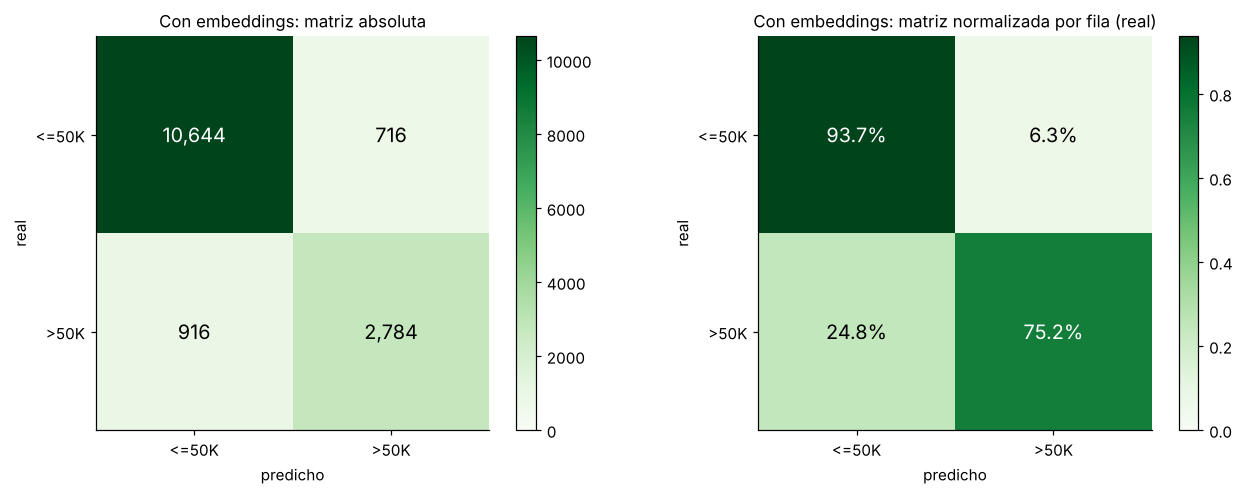

In [13]:
# b) Classification report y matrices de confusión (validation)
NOMBRES = ["<=50K", ">50K"]

def reporte_y_matrices(modelo, datos, titulo, color):
    y = datos["validation"][2].numpy().ravel().astype(int)
    pred = (predecir(modelo, datos["validation"]) >= 0.5).astype(int)
    print(classification_report(y, pred, target_names=NOMBRES, digits=4))
    cm = confusion_matrix(y, pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for ax, mat, fmt, sub in [(axes[0], cm, "{:,.0f}", "absoluta"), (axes[1], cm_norm, "{:.1%}", "normalizada por fila (real)")]:
        im = ax.imshow(mat, cmap=color, vmin=0)
        for i in range(2):
            for j in range(2):
                v = mat[i, j]
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=13,
                        color="white" if v > mat.max() * 0.6 else "black")
        ax.set_xticks([0, 1], NOMBRES); ax.set_yticks([0, 1], NOMBRES); ax.grid(False)
        ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title(f"{titulo}: matriz {sub}")
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.show()
    return y, pred

y_val, pred_emb = reporte_y_matrices(modelo_emb, DATOS["embeddings"], "Con embeddings", "Greens")


- La clase <=50K, la mayoritaria, se predice muy bien: precision 0,92, recall 0,94, F1 0,93.
- La clase >50K es la difícil: precision 0,80 y recall 0,75. De cada 4 personas que realmente ganan más de 50K, el modelo detecta 3 (la matriz normalizada lo muestra: 75,2% bien clasificadas y 24,8% confundidas con <=50K). Cuando el modelo dice ">50K", acierta en el 80% de los casos.
- En números absolutos, los errores se reparten en 916 personas de >50K que el modelo no detectó y 716 de <=50K que clasificó como >50K.

El F1 macro (0,851) es el promedio simple del F1 de las dos clases, así que la clase minoritaria pesa lo mismo que la mayoritaria. Por eso queda por debajo de la accuracy (0,892), que está dominada por la clase <=50K.

##### ¿Qué aprendieron los embeddings?

Un embedding es útil si ubica cerca a las categorías que se comportan parecido. Para verlo, dibujamos el vector aprendido de cada ocupación (tiene 2 dimensiones, así que se grafica directo) y el de cada skill-profile (tiene 5, así que lo proyectamos a 2 con PCA). Cada punto está coloreado según el % de >50K de esa categoría en train. La red nunca recibió ese porcentaje como dato: si los colores quedan ordenados, es porque lo aprendió sola.

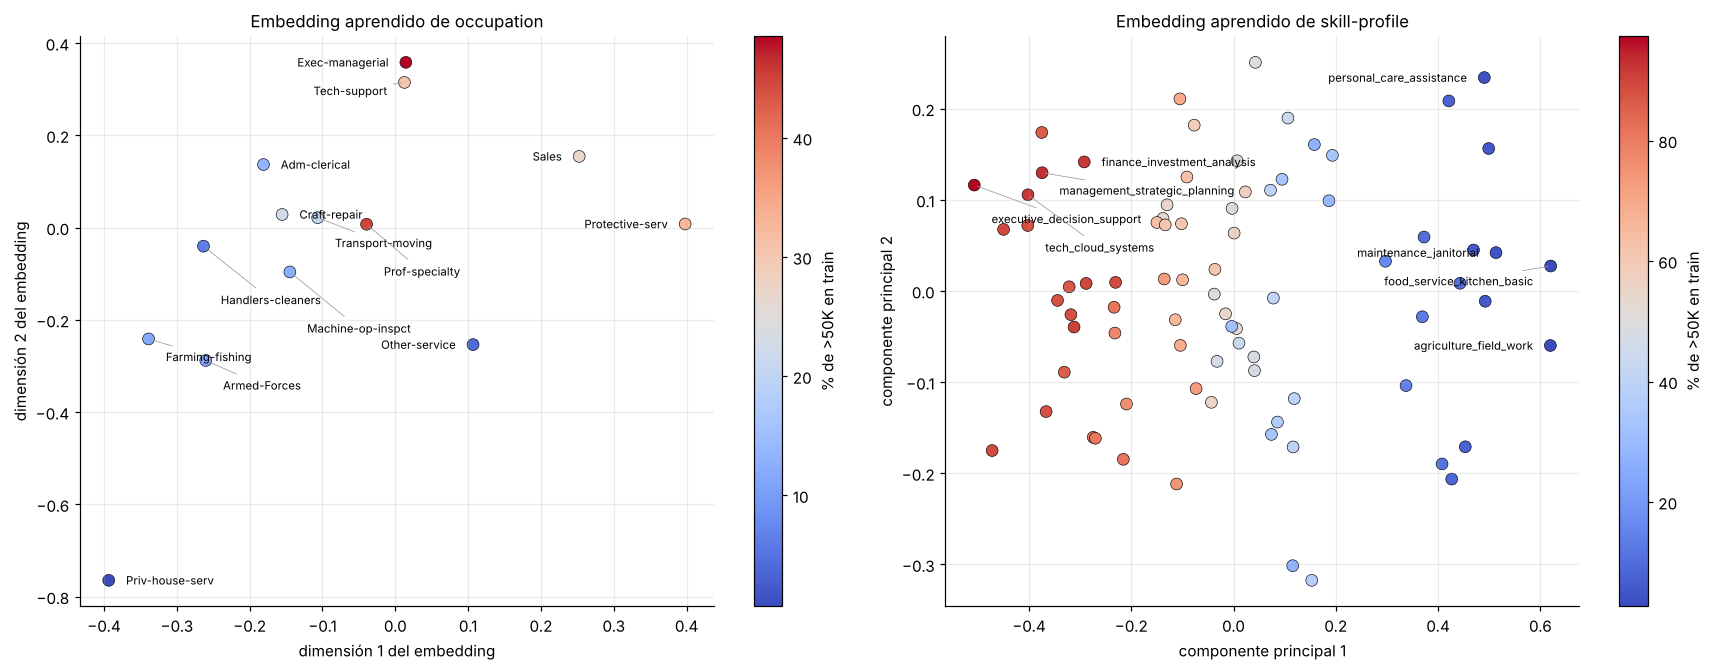

occupation: correlación (Spearman) entre la componente principal del embedding y el % de >50K = 0.85
skill-profile: correlación (Spearman) entre la componente principal del embedding y el % de >50K = 0.97


In [14]:
# b) ¿Qué aprendieron los embeddings? Vectores de occupation (2 dimensiones) y de skill-profile (proyectados a 2D)
tasa_ocup = 100 * y_train.groupby(train_raw["occupation"]).mean()
tasa_skill = 100 * y_train.groupby(train_raw["skill-profile"]).mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
for ax, col, tasa in [(axes[0], "occupation", tasa_ocup), (axes[1], "skill-profile", tasa_skill)]:
    emb = modelo_emb.embeddings[EMB_COLS.index(col)].weight.detach().numpy()
    vocab = prep.vocab_emb[col]
    vec = np.array([emb[vocab[v]] for v in tasa.index])
    if vec.shape[1] > 2:                                     # proyección a 2D con PCA (sklearn)
        from sklearn.decomposition import PCA
        vec = PCA(n_components=2, random_state=SEED).fit_transform(vec)
        ax.set_xlabel("componente principal 1"); ax.set_ylabel("componente principal 2")
    else:
        ax.set_xlabel("dimensión 1 del embedding"); ax.set_ylabel("dimensión 2 del embedding")
    sc = ax.scatter(vec[:, 0], vec[:, 1], c=tasa.values, cmap="coolwarm", s=60, edgecolor="k", lw=0.4)
    etiquetas = tasa.index if col == "occupation" else list(tasa.nsmallest(4).index) + list(tasa.nlargest(4).index)
    # Ubicación de las etiquetas: se ordenan por altura y se separan verticalmente las que quedarían encimadas
    rango_x, rango_y = np.ptp(vec[:, 0]), np.ptp(vec[:, 1])
    x_medio = vec[:, 0].min() + rango_x / 2
    ubicadas = []
    for nombre in sorted(etiquetas, key=lambda n: -vec[list(tasa.index).index(n), 1]):
        i = list(tasa.index).index(nombre)
        x, y = vec[i]
        lado = -1 if x > x_medio else 1                      # las de la mitad derecha se escriben hacia la izquierda
        ty = y
        for ux, uy, ul in ubicadas:
            if ul == lado and abs(ux - x) < 0.35 * rango_x and abs(uy - ty) < 0.055 * rango_y:
                ty = uy - 0.055 * rango_y
        ubicadas.append((x, ty, lado))
        ax.annotate(nombre, (x, y), xytext=(x + lado * 0.03 * rango_x, ty), fontsize=7.5,
                    ha="left" if lado == 1 else "right", va="center",
                    arrowprops=dict(arrowstyle="-", color="0.6", lw=0.5) if abs(ty - y) > 0.01 * rango_y else None)
    plt.colorbar(sc, ax=ax, label="% de >50K en train")
    ax.set_title(f"Embedding aprendido de {col}")
plt.tight_layout(); plt.show()

from scipy.stats import spearmanr
for col, tasa in [("occupation", tasa_ocup), ("skill-profile", tasa_skill)]:
    emb = modelo_emb.embeddings[EMB_COLS.index(col)].weight.detach().numpy()
    vec = np.array([emb[prep.vocab_emb[col][v]] for v in tasa.index])
    from sklearn.decomposition import PCA
    pc1 = PCA(n_components=1, random_state=SEED).fit_transform(vec).ravel()
    print(f"{col}: correlación (Spearman) entre la componente principal del embedding y el % de >50K = "
          f"{abs(spearmanr(pc1, tasa.values).correlation):.2f}")


Los embeddings aprendieron algo con sentido.

- En occupation, Exec-managerial y Tech-support quedan arriba, juntos y en rojo (alto % de >50K), y Priv-house-serv queda sola en el extremo opuesto, en azul. Hay una excepción: Prof-specialty, que tiene 45% de >50K, queda en el medio del grupo. Con solo 2 dimensiones la red tiene que acomodar 14 ocupaciones y no todo entra perfecto.
- En skill-profile es todavía más claro: a la izquierda están los skills de alto ingreso (executive_decision_support, management_strategic_planning, tech_cloud_systems) y a la derecha los de bajo ingreso (food_service_kitchen_basic, agriculture_field_work, maintenance_janitorial). La primera componente del embedding tiene una correlación de 0,97 con el % de >50K de cada skill.

En ningún momento le dimos a la red el porcentaje de cada categoría. Lo dedujo sola a partir de los ejemplos. Esto también explica el experimento de inicialización: con N(0, 1) este orden casi no aparecía, porque los vectores aleatorios iniciales eran demasiado grandes para moverse.

## c) Diseño y entrenamiento de un modelo sin embeddings (3 puntos)

- Entrenar un segundo modelo, aplicando one-hot encoding a todas las variables que en el punto b) fueron representadas mediante embeddings.
- Quitar todas las capas de dropout, para este segundo modelo no se usará ninguna capa interna de regularización.
- Con respecto al resto de capas, se debe mantener exactamente la misma arquitectura del modelo anterior: igual número de capas, misma cantidad de neuronas por capa y mismas funciones de activación.
- Presentar las mismas métricas, visualizaciones y reportes que en el modelo con embeddings.

### Resolución c)

Mismo pipeline y misma red, con dos cambios que pide la consigna: `occupation`, `native-country` y `skill-profile` pasan a one-hot, y no hay ninguna capa de Dropout (`RedTabular` con `dropout=0` no las crea). Se mantienen las capas ocultas de 128, 64 y 32 neuronas, la LeakyReLU, Adam con 0,001, el batch de 256, las 40 épocas y el mismo early stopping con el set de ajuste, para que la comparación sea justa.

RedTabular(
  (embeddings): ModuleList()
  (mlp): Sequential(
    (0): Linear(in_features=166, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Entradas al MLP: 166 (con embeddings eran 42)


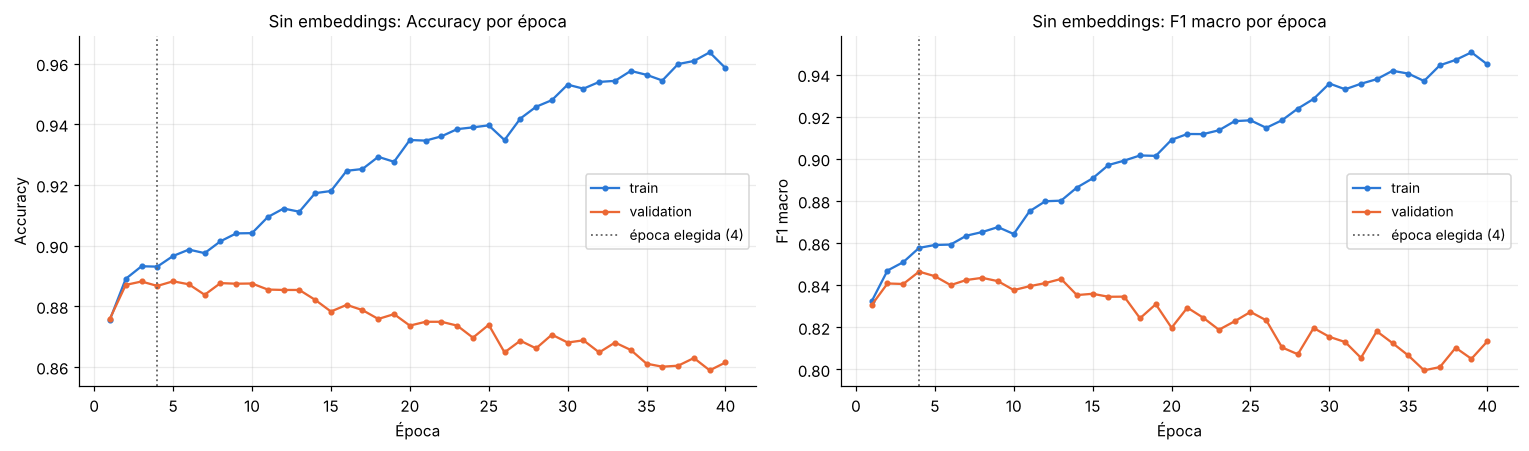

Época elegida 4: accuracy train 0.8931 | validation 0.8867  ·  F1 macro train 0.8577 | validation 0.8464
Última época: F1 macro train 0.9448 | validation 0.8133


In [15]:
# c) Modelo sin embeddings: occupation, native-country y skill-profile pasan a one-hot y se quitan todas las capas de dropout.
#    Todo lo demás queda igual: mismas capas ocultas, mismas neuronas, misma activación, mismo optimizador y protocolo.
CONFIG_OH = {**CONFIG_EMB, "modo": "onehot", "dropout": 0.0}
modelo_oh, hist_oh, mejor_oh, seg_oh = entrenar(CONFIG_OH, semilla=SEED)
print(modelo_oh)
print(f"Entradas al MLP: {modelo_oh.n_entradas} (con embeddings eran {modelo_emb.n_entradas})")
graficar_curvas(hist_oh, mejor_oh, "Sin embeddings")


El contraste con b) es claro. Validation alcanza su mejor valor en la época 4 (F1 macro 0,846) y desde ahí baja de forma sostenida, mientras train sigue subiendo hasta 0,945. En la época 40, validation cae a 0,813 y la brecha llega a 0,13, más de cinco veces la del modelo con embeddings. Esto es sobreajuste: con 166 entradas, 31.745 parámetros y nada que lo frene, la red memoriza a las personas de train.

El early stopping lo rescata porque se queda con la época 4. Pero hay que tenerlo en cuenta: este modelo solo funciona bien si se corta el entrenamiento casi al principio, y un par de épocas de más ya lo empeoran.

              precision    recall  f1-score   support

       <=50K     0.9229    0.9273    0.9251     11360
        >50K     0.7735    0.7622    0.7678      3700

    accuracy                         0.8867     15060
   macro avg     0.8482    0.8447    0.8464     15060
weighted avg     0.8862    0.8867    0.8864     15060



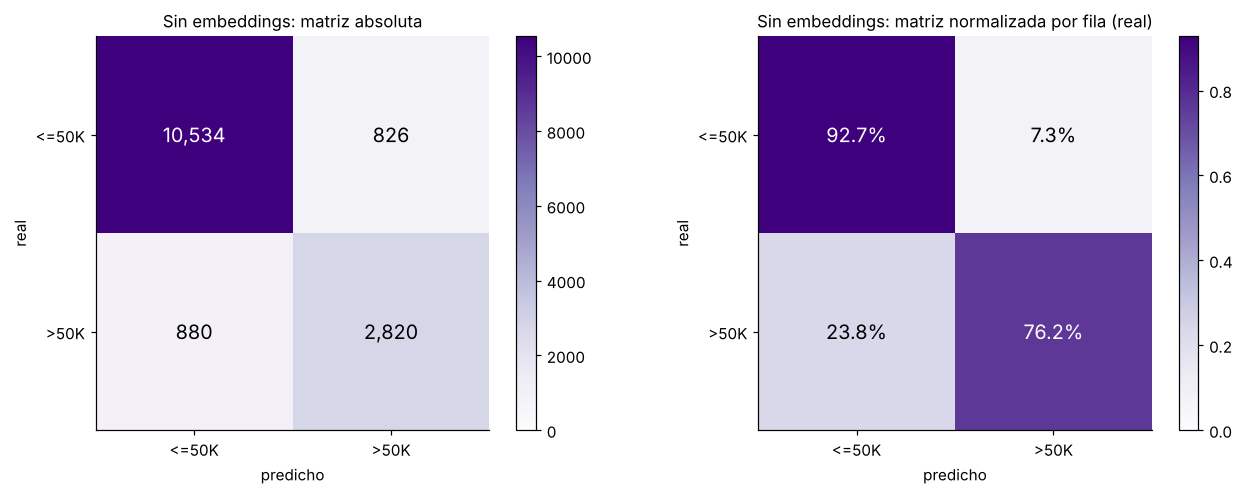

In [16]:
# c) Classification report y matrices de confusión (validation)
_, pred_oh = reporte_y_matrices(modelo_oh, DATOS["onehot"], "Sin embeddings", "Purples")


En la época que eligió el early stopping, los resultados se parecen mucho a los de b): accuracy 0,887 y F1 macro 0,846. Este modelo detecta un poco más de casos de >50K (recall 0,76 contra 0,75), pero con más falsos positivos (precision 0,77 contra 0,80). Las matrices muestran el mismo patrón: 76,2% de los >50K bien clasificados, y 7,3% de los <=50K confundidos con >50K, contra 6,3% del modelo con embeddings.


## d) Conclusiones finales (2 puntos)

- Elaborar una tabla comparativa con los resultados obtenidos por ambos modelos. No solo comparar métricas de precisión, sino también la cantidad final de parámetros y entradas.
- Redactar detalladamente sus observaciones y apreciaciones derivadas de la comparación y plantear conclusiones fundamentadas respecto al desempeño de cada enfoque, justificando por qué uno funciona mejor o peor según las características del problema.

### Resolución d)

##### Tabla comparativa

Además de las métricas de clasificación, comparamos lo que se señaló en clase como ventaja de los embeddings: cuántas entradas recibe la red, cuántos parámetros tiene, cuánto pesa el archivo del modelo guardado y cuánto tarda en entrenar. Todas las métricas son sobre validation.

In [17]:
# d) Tabla comparativa de los dos modelos pedidos
def resumen_modelo(nombre, modelo, datos, hist, mejor, seg):
    p = predecir(modelo, datos["validation"]); y = datos["validation"][2].numpy().ravel().astype(int)
    pred = (p >= 0.5).astype(int)
    f1_clase = f1_score(y, pred, average=None)
    total, emb = contar_parametros(modelo)
    e = mejor["epoca"] - 1
    return {"modelo": nombre,
            "accuracy": accuracy_score(y, pred), "F1 macro": f1_score(y, pred, average="macro"),
            "F1 <=50K": f1_clase[0], "F1 >50K": f1_clase[1],
            "recall >50K": (pred[y == 1] == 1).mean(), "precision >50K": (y[pred == 1] == 1).mean(),
            "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "entradas al MLP": modelo.n_entradas, "columnas del dataset transformado": datos["train"][0].shape[1] + datos["train"][1].shape[1],
            "parámetros totales": total, "parámetros en embeddings": emb,
            "peso del archivo (KB)": peso_en_disco(modelo), "segundos por época": seg,
            "época elegida": mejor["epoca"],
            "brecha F1 train - val (época elegida)": hist["f1_macro_train"][e] - hist["f1_macro_validation"][e],
            "F1 macro val sin early stopping (época 40)": hist["f1_macro_validation"][-1],
            "brecha F1 train - val (época 40)": hist["f1_macro_train"][-1] - hist["f1_macro_validation"][-1]}

comparacion = pd.DataFrame([resumen_modelo("b) con embeddings + dropout", modelo_emb, DATOS["embeddings"], hist_emb, mejor_emb, seg_emb),
                            resumen_modelo("c) one-hot sin dropout", modelo_oh, DATOS["onehot"], hist_oh, mejor_oh, seg_oh)]).set_index("modelo").T
fmt = lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.4f}"
display(comparacion.style.format(fmt))


modelo,b) con embeddings + dropout,c) one-hot sin dropout
accuracy,0.8916,0.8867
F1 macro,0.8511,0.8464
F1 <=50K,0.9288,0.9251
F1 >50K,0.7733,0.7678
recall >50K,0.7524,0.7622
precision >50K,0.7954,0.7735
ROC-AUC,0.9440,0.9407
PR-AUC,0.8625,0.8521
entradas al MLP,42.0000,166
columnas del dataset transformado,34.0000,166


- En precisión, con early stopping, el modelo con embeddings queda apenas arriba: accuracy 0,892 contra 0,887, F1 macro 0,851 contra 0,846, ROC-AUC 0,944 contra 0,941. Son diferencias chicas, del orden de lo que cambia entre semillas (lo medimos en la tabla siguiente).
- En tamaño, la diferencia es grande. El modelo con embeddings recibe 42 entradas en lugar de 166, tiene 16.476 parámetros en lugar de 31.745 (48% menos) y su archivo pesa 68 KB en lugar de 127 KB. Casi toda la diferencia está en la primera capa: con one-hot, cada una de las 135 columnas de occupation, native-country y skill-profile tiene 128 pesos propios. Con embeddings, esas tres variables entran como 11 números, y los vectores de las 135 categorías suman solo 603 parámetros.
- En estabilidad, la diferencia es todavía mayor. Sin early stopping, en la época 40, el modelo con embeddings mantiene 0,852 de F1 macro, mientras que el one-hot sin dropout cae a 0,813. La brecha entre train y validation es 0,023 contra 0,132.
- En tiempo, el one-hot es un poco más rápido por época (en esta corrida, 0,35 s contra 0,42 s; el número exacto cambia según la máquina). Con una red tan chica, el costo de buscar los vectores de embedding pesa más que el ahorro en multiplicaciones. Con miles de categorías la cuenta se daría vuelta, pero acá no se nota.

##### ¿Qué parte de la diferencia viene de los embeddings y qué parte del dropout?

La comparación que pide la consigna cambia dos cosas a la vez: el modelo b) tiene embeddings y dropout, y el c) no tiene ninguna de las dos. Para separar el efecto de cada una entrenamos también los dos casos intermedios (embeddings sin dropout y one-hot con dropout), todos con 3 semillas. Mostramos el F1 de validation con early stopping y también sin él (en la época 40), que es donde se ve cuánto sobreajusta cada variante.

,F1 macro val,± desvío,accuracy val,F1 macro val sin early stopping (época 40),brecha F1 train-val en la época 40,parámetros
variante,,,,,,
embeddings + dropout (b),0.8481,0.0033,0.8906,0.8492,0.0223,"16,476"
embeddings sin dropout,0.8479,0.0008,0.8884,0.8428,0.0413,"16,476"
one-hot + dropout,0.8438,0.0005,0.8876,0.8317,0.0765,"31,745"
one-hot sin dropout (c),0.8465,0.0008,0.8881,0.8197,0.1158,"31,745"


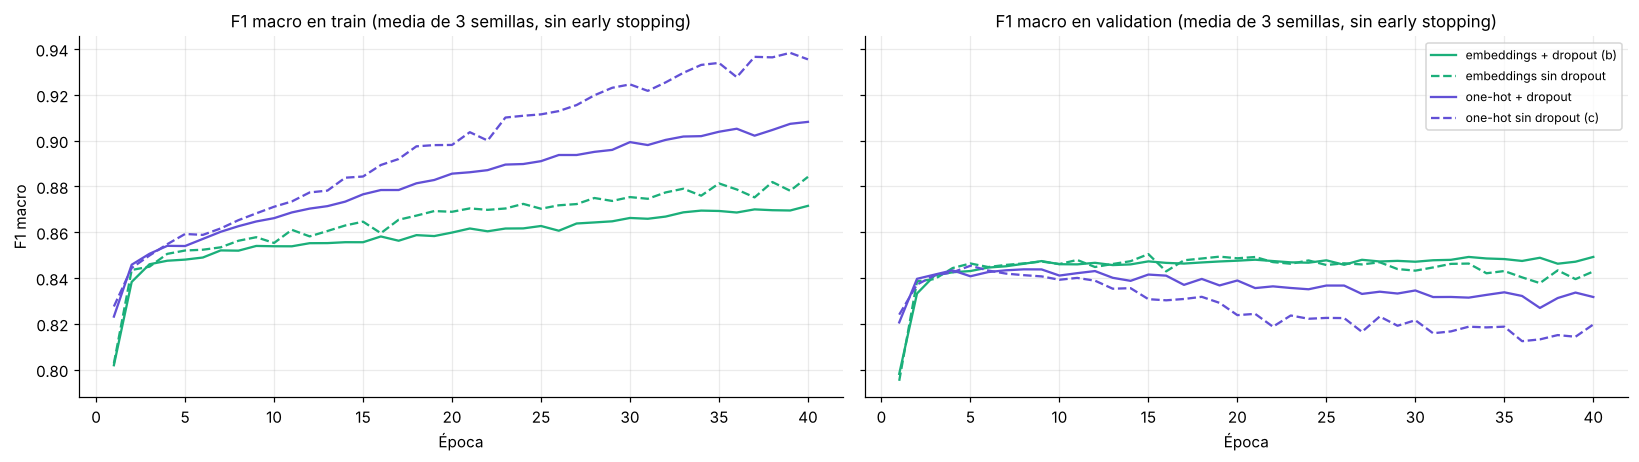

In [18]:
# d) ¿Qué parte de la diferencia es por los embeddings y qué parte por el dropout? Diseño 2 x 2, 3 semillas cada uno
variantes_2x2 = {
    "embeddings + dropout (b)": {**CONFIG_EMB},
    "embeddings sin dropout": {**CONFIG_EMB, "dropout": 0.0},
    "one-hot + dropout": {**CONFIG_EMB, "modo": "onehot"},
    "one-hot sin dropout (c)": {**CONFIG_OH},
}
filas, hist_2x2 = [], {}
for nombre, cfg in variantes_2x2.items():
    for s in SEMILLAS:
        modelo, h, mejor, seg = entrenar(cfg, semilla=s)
        hist_2x2[(nombre, s)] = h
        m = metricas(modelo, DATOS[cfg["modo"]]["validation"])
        filas.append({"variante": nombre, "semilla": s, "F1 macro val": m["f1_macro"], "accuracy val": m["accuracy"],
                      "F1 val época 40": h["f1_macro_validation"][-1],
                      "brecha F1 (época 40)": h["f1_macro_train"][-1] - h["f1_macro_validation"][-1],
                      "parámetros": contar_parametros(modelo)[0]})
res = pd.DataFrame(filas)
tabla_2x2 = res.groupby("variante", sort=False).agg(**{
    "F1 macro val": ("F1 macro val", "mean"), "± desvío": ("F1 macro val", "std"),
    "accuracy val": ("accuracy val", "mean"), "F1 macro val sin early stopping (época 40)": ("F1 val época 40", "mean"),
    "brecha F1 train-val en la época 40": ("brecha F1 (época 40)", "mean"),
    "parámetros": ("parámetros", "first")})
display(tabla_2x2.style.format({"F1 macro val": "{:.4f}", "± desvío": "{:.4f}", "accuracy val": "{:.4f}",
                                "F1 macro val sin early stopping (época 40)": "{:.4f}",
                                "brecha F1 train-val en la época 40": "{:.4f}", "parámetros": "{:,.0f}"})
        .set_caption("Validation (media de 3 semillas). Las dos primeras columnas usan early stopping con el set de ajuste"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
estilo = {"embeddings + dropout (b)": (C_EMB, "-"), "embeddings sin dropout": (C_EMB, "--"),
          "one-hot + dropout": (C_OH, "-"), "one-hot sin dropout (c)": (C_OH, "--")}
for ax, split in zip(axes, ["train", "validation"]):
    for nombre in variantes_2x2:
        curvas = np.array([h[f"f1_macro_{split}"] for (n, _), h in hist_2x2.items() if n == nombre])
        color, ls = estilo[nombre]
        ax.plot(np.arange(1, curvas.shape[1] + 1), curvas.mean(axis=0), color=color, ls=ls, label=nombre)
    ax.set_title(f"F1 macro en {split} (media de 3 semillas, sin early stopping)"); ax.set_xlabel("Época")
axes[0].set_ylabel("F1 macro"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


- Con early stopping, las cuatro variantes quedan a menos de 0,005 de F1 macro entre sí (de 0,844 a 0,848). Si uno corta el entrenamiento en el momento justo, la forma de codificar casi no cambia la precisión final en este dataset.
- Sin early stopping aparece la diferencia, y se ve que los embeddings pesan más que el dropout. En la época 40, pasar de one-hot a embeddings (los dos sin dropout) mejora el F1 de 0,820 a 0,843. Agregar dropout a one-hot lo mejora de 0,820 a 0,832. Con las dos cosas juntas se llega a 0,849.
- La brecha entre train y validation va bajando en el mismo orden: 0,116 (one-hot sin dropout), 0,076 (one-hot con dropout), 0,041 (embeddings sin dropout) y 0,022 (embeddings con dropout). Los embeddings funcionan como una regularización propia: le dan a la red menos parámetros y la obligan a describir cada categoría con pocos números, que se comparten entre las categorías parecidas.
- Las curvas de la izquierda muestran lo mismo desde train: las variantes one-hot siguen subiendo hasta 0,91-0,94 porque memorizan, y las de embeddings se quedan cerca de 0,87-0,89.

### Conclusiones finales

#### Qué encontramos

El modelo con embeddings y dropout logra la misma precisión que el one-hot, o un poco más: accuracy 0,892 y F1 macro 0,851, contra 0,887 y 0,846. Lo hace con la mitad de parámetros (16.476 contra 31.745), un cuarto de las entradas (42 contra 166) y un archivo de la mitad del tamaño (68 KB contra 127 KB). Además es mucho más estable: no necesita que se corte el entrenamiento en el momento justo. Con 40 épocas completas sigue en 0,852, mientras que el one-hot sin dropout cae a 0,813.

#### Por qué funciona mejor

- One-hot trata a cada categoría como una columna aislada, a la misma distancia de todas las demás. Para la red, "tech_cloud_systems" y "tech_software_engineering" son tan distintos entre sí como cualquiera de los dos y "agriculture_field_work". Cada una de las 135 columnas tiene sus propios 128 pesos en la primera capa, que se aprenden solo con las personas de esa categoría. En categorías con pocos casos, como los países con 1 a 15 personas o Armed-Forces con 9, eso termina en memorización. Es lo que muestran las curvas de c).
- Un embedding describe cada categoría con pocos números (2 a 5) que se ajustan para predecir. Las categorías que se comportan parecido terminan con vectores parecidos, y lo pudimos ver: el embedding de skill-profile quedó ordenado según el ingreso, con una correlación de 0,97, sin que nadie se lo indicara. Así, una categoría con pocos casos se beneficia de lo que la red aprendió de las parecidas.
- Por qué la ventaja en precisión es chica: 30 mil personas es bastante para la cantidad de categorías que hay, y las variables más importantes (relationship, education, edad, capital) son las mismas en los dos modelos. La diferencia se nota en la estabilidad y en el tamaño más que en la accuracy.

#### Detalles que importaron

- La inicialización de los embeddings fue la decisión que más movió el resultado (+0,008 de F1). Con la inicialización por defecto de PyTorch, N(0, 1), los vectores arrancan demasiado grandes, la red los usa como códigos fijos y no aprende la estructura. Con N(0, 0,1) sí la aprende. En clase se recomendó inicializar con una distribución normal, y acá se ve que también importa con qué desvío.
- La regla de raíz(n)/2 para la dimensión funcionó bien desde el principio: duplicarla no mejoró nada y solo agregó parámetros.
- Darle más peso a la clase minoritaria no mejoró el F1 macro. Solo corre el punto de equilibrio entre detectar más >50K y equivocarse más con los <=50K. Sería útil si el negocio necesitara priorizar alguna de las dos clases.

#### Limitaciones

- Las diferencias de precisión entre los dos modelos son chicas (0,002 a 0,005 de F1 macro según la semilla). Con estos datos no se puede afirmar que uno clasifique mejor que el otro. Lo que sí se sostiene en las 3 semillas son las diferencias de tamaño y de sobreajuste.
- Validation solo se usó para reportar, y las decisiones se tomaron con un 15% separado de train. Aun así, es un único conjunto de evaluación: un set de test aparte daría una medición todavía más independiente.
- skill-profile es la variable que más separa la clase (AUC 0,87 por sí sola) y no existe en el Adult original. Parte del buen desempeño de los dos modelos depende de ella.